# Single-cell multi-omics lineage tracing (re-analysis of Liu et al., 2026 data)

This tutorial showcases the interoperability of MiTo with the scverse ecosystem for complex clonally-resolved single-cell multi-omics.
We analyse mtscATAC-seq data from [Liu et al., 2026](https://doi.org/10.1016/j.ccell.2026.05.006) [1], using
[SnapATAC2](https://snapatac2.scverse.org) [2] for cell type annotation and [MiTo](https://mito.readthedocs.io) [3] for clonal inference.

In mtscATAC-seq every cell gives two readouts: nuclear fragments (chromatin accessibility, which we use to say *what* each cell is)
and mitochondrial reads (mtDNA variants, which we use as natural lineage marks to say *which clone* it belongs to).
We annotate the cells, build the clones, join the two, and ask which clones are enriched in specific cell types.

For cell annotation, we follow the steps of the [SnapATAC2 PBMC tutorial](https://snapatac2.scverse.org/tutorials/pbmc.html) and
the [single-cell best practices](https://www.sc-best-practices.org/chromatin-accessibility/introduction/) [4].

1. QC
2. 500-bp tiles, spectral embedding, UMAP
3. gene activity and broad lineages
4. re-embedding, islands, curation
5. clusters, epithelial cell types, immune cell types
6. coverage support of each cell type
7. final result
8. MT lineage tracing and joining
9. clones enriched in specific cell types

References are listed at the end.

## Dataset

Liu et al. follow clones of immune cells in human cancer with mtDNA variants (GEO [GSE302113](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE302113)).
We use the mtscATAC-seq libraries of one donor, **SU-L-005**: seven samples from three tissues (tumor, non-involved lung tissue `NILT`, blood `PBMC`),
each sorted by FACS into a fraction (CD3+ T cells, CD3- other leukocytes, CD45- epithelial and stromal cells). The sort design drives the cell type
composition of each sample, and we keep it in mind when reading the results.

| Sample | Tissue | FACS fraction |
|---|---|---|
| GSM9096489 | tumor | CD3+ |
| GSM9096490 | tumor | CD3- / CD45- |
| GSM9096491 | NILT | CD3+ |
| GSM9096492 | NILT | CD3- |
| GSM9096493 | NILT | CD45- |
| GSM9096494 | PBMC | CD3+ |
| GSM9096495 | PBMC | CD3- |

**Input.** Two objects with the same cells:

* the **loose merged ATAC object**: the seven samples together, with the cells that have TSSE >= 5 and >= 500 fragments (67,027 cells), their fragments,
  and a doublet score computed per sample with Scrublet [5];
* the **merged allele-frequency matrix (AFM)** of the mitochondrial variants (50,095 cells x 49,708 candidate MT-SNVs, molecule counts), built from the same libraries as described in
  [Loading data](https://mito.readthedocs.io/en/stable/loading_data.html).

## Environment

The tutorial runs in a conda environment with SnapATAC2 and MiTo. The versions below are the ones the results were produced with
(file: [liu2026_environment.yml](https://github.com/andrecossa5/MiTo/blob/master/docs/source/liu2026_environment.yml)):

```yaml
name: mito-liu2026
channels:
  - conda-forge
dependencies:
  - python=3.11
  - pip
  - pip:
      - scmito==2.0.1
      - snapatac2==2.9.0
      - scanpy==1.11.5
      - anndata==0.12.19
      - numpy==2.4.6
      - pandas==2.3.3
      - scipy==1.17.1
      - scikit-learn==1.9.1
      - statsmodels==0.14.6
      - matplotlib==3.11.2
      - seaborn==0.13.2
      - igraph==1.0.0
      - leidenalg==0.12.0
      - polars==1.44.2
      - pynndescent==0.6.0       # 0.7 breaks scanpy 1.11
      - umap-learn==0.5.12
      - numba==0.68.0
      - ipykernel==7.4.0
```

```bash
conda env create -f liu2026_environment.yml
conda activate mito-liu2026
python -m ipykernel install --user --name mito-liu2026
jupyter lab                                # and pick this kernel
```

The C/C++ toolchain that MiTo needs is described in the [installation guide](https://mito.readthedocs.io/en/stable/installation.html).

**Resources.** The data are one download of 2.9 GB (a tar that the notebook unpacks, and then deletes). The notebook needs about 9 GB of memory at its peak and writes about 5 GB of intermediate files (tile matrices), which the last cell deletes.
On an Apple-silicon laptop it ran in about 15 minutes, half of them in the MT part.

## 0. Setup

In [1]:
import warnings
warnings.filterwarnings('ignore')

import gzip
import hashlib
import logging
import os
import pickle
import re
import tarfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from sklearn.neighbors import NearestNeighbors

import snapatac2 as snap
import snapatac2._snapatac2 as snap_internal   # coverage, as used by snap.pl.coverage (a private function: it can change between SnapATAC2 versions)
import plotting_utils as plu

logging.getLogger().setLevel(logging.WARNING)

# One style for the whole notebook: scanpy defaults first, plotting_utils style on top
sc.set_figure_params(dpi=90, frameon=False, fontsize=9, figsize=(3.2, 3.2))
plu.set_rcParams({
    'figure.dpi': 90,
    'figure.figsize': (3.2, 3.2),
    'font.size': 9,
    'axes.titlesize': 9,
    'axes.labelsize': 9,
    'legend.fontsize': 8,
    'axes.grid': False,    # scanpy turns the grid on
})

In [2]:
# Data: one archive on Zenodo, downloaded and unpacked once into DATA_DIR. Everything the notebook writes goes to OUT.
ZENODO_RECORD = '23912759'                  # https://doi.org/10.5281/zenodo.23912759
ARCHIVE = 'liu2026_SU-L-005.tar'
ARCHIVE_MD5 = '0e1180ed2b2d8c8f0dbaf072ad92c71c'
DATA_DIR = Path(os.environ.get('MITO_LIU_DATA', 'liu2026_data')).resolve()
OUT = Path(os.environ.get('MITO_LIU_RESULTS', 'liu2026_results')).resolve()
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)

LOOSE = DATA_DIR / 'atac_merged.h5ad'                          # loose ATAC object
AFM_FILE = DATA_DIR / 'mt_merged_ma.h5ad'                      # merged AFM
REFERENCE_CELLS = DATA_DIR / 'reference_cells.csv'             # outputs of this notebook, to check a run
REFERENCE_ENRICHMENT = DATA_DIR / 'reference_clone_celltype_enrichment.csv'


def md5sum(path):
    digest = hashlib.md5()
    with open(path, 'rb') as handle:
        for block in iter(lambda: handle.read(1 << 24), b''):
            digest.update(block)
    return digest.hexdigest()


if not all(path.exists() for path in (LOOSE, AFM_FILE, REFERENCE_CELLS, REFERENCE_ENRICHMENT)):
    archive = DATA_DIR / ARCHIVE
    if not (archive.exists() and md5sum(archive) == ARCHIVE_MD5):
        print(f'downloading {ARCHIVE} (2.9 GB) ...')
        urllib.request.urlretrieve(f'https://zenodo.org/records/{ZENODO_RECORD}/files/{ARCHIVE}?download=1', archive)
        assert md5sum(archive) == ARCHIVE_MD5, 'the checksum does not match: delete the file and download it again'
    with tarfile.open(archive) as tar:
        tar.extractall(DATA_DIR, filter='data')
    archive.unlink()                                           # the archive is not needed once unpacked

print(f'data in {DATA_DIR.name}/:', sorted(path.name for path in DATA_DIR.iterdir()))
print(f'results go to {OUT.name}/')

SAMPLES = {
    'GSM9096489': 'tumor CD3+',
    'GSM9096490': 'tumor CD3-/CD45-',
    'GSM9096491': 'NILT CD3+',
    'GSM9096492': 'NILT CD3-',
    'GSM9096493': 'NILT CD45-',
    'GSM9096494': 'PBMC CD3+',
    'GSM9096495': 'PBMC CD3-',
}
TISSUE = {gsm: name.split()[0] for gsm, name in SAMPLES.items()}

PALETTE = {
    'tumor': '#d62728',
    'NILT': '#2ca02c',
    'PBMC': '#1f77b4',
    'T/NK': '#1f77b4',
    'B/plasma': '#2ca02c',
    'Myeloid': '#d62728',
    'Non-immune': '#8c564b',
    'unassigned': '#d9d9d9',
}


def set_colors(adata, key, palette):
    # give the categories of adata.obs[key] the colours of the palette (for scanpy plots)
    values = adata.obs[key].astype(str)
    categories = [name for name in palette if name in set(values)]
    categories += sorted(set(values) - set(categories))      # names without a colour stay grey
    adata.obs[key] = pd.Categorical(values, categories=categories)
    adata.uns[f'{key}_colors'] = [palette.get(name, '#999999') for name in categories]

data in liu2026_SU-L-005/: ['atac_merged.h5ad', 'mt_merged_ma.h5ad', 'reference_cells.csv', 'reference_clone_celltype_enrichment.csv']
results go to results/


## 1. Quality control

A cell has to be told from an empty droplet or a damaged nucleus. Two numbers do most of the work: the **unique fragments** (depth) and the
**TSS enrichment** (signal-to-noise: in an intact nucleus the fragments pile up around transcription start sites). The loose object already drops
the worst barcodes, so here we only refine the cut. We read both metrics per sample, set a threshold for each sample, and keep the cells above both.

In [3]:
loose = snap.read(LOOSE)

obs = loose.obs[:].to_pandas()
obs.index = list(loose.obs_names)
obs['tissue'] = obs['sample'].map(TISSUE)
obs['log_fragments'] = np.log10(obs['n_fragment'])

print(f'{len(obs):,} cells')
obs.groupby('sample')[['n_fragment', 'tsse', 'frac_dup']].median().rename(index=SAMPLES).round(2)

67,027 cells


,n_fragment,tsse,frac_dup
sample,,,
tumor CD3+,5982.0,26.30,0.77
tumor CD3-/CD45-,3777.0,15.58,0.38
NILT CD3+,1975.0,20.64,0.76
NILT CD3-,3329.0,15.21,0.44
NILT CD45-,4838.0,14.14,0.59
PBMC CD3+,4690.5,27.04,0.50
PBMC CD3-,7393.5,25.68,0.56


Samples differ in depth and TSS enrichment: the CD3-/CD45- fractions are intrinsically lower in TSSE
and NILT CD3+ is shallow, so one global threshold would cut some samples much harder than others.
We judge each cell against **its own sample**. A cell is kept if

* TSSE >= max(8, 0.5 x the sample median), and
* unique fragments >= max(1,000, 0.25 x the sample median).

In [4]:
median = obs.groupby('sample')[['tsse', 'n_fragment']].median()

thresholds = pd.DataFrame({
    'tsse_min': np.maximum(8, 0.5 * median['tsse']),
    'fragments_min': np.maximum(1000, 0.25 * median['n_fragment']),
})

min_tsse = obs['sample'].map(thresholds['tsse_min'])
min_fragments = obs['sample'].map(thresholds['fragments_min'])
obs['keep'] = (obs['tsse'] >= min_tsse) & (obs['n_fragment'] >= min_fragments)

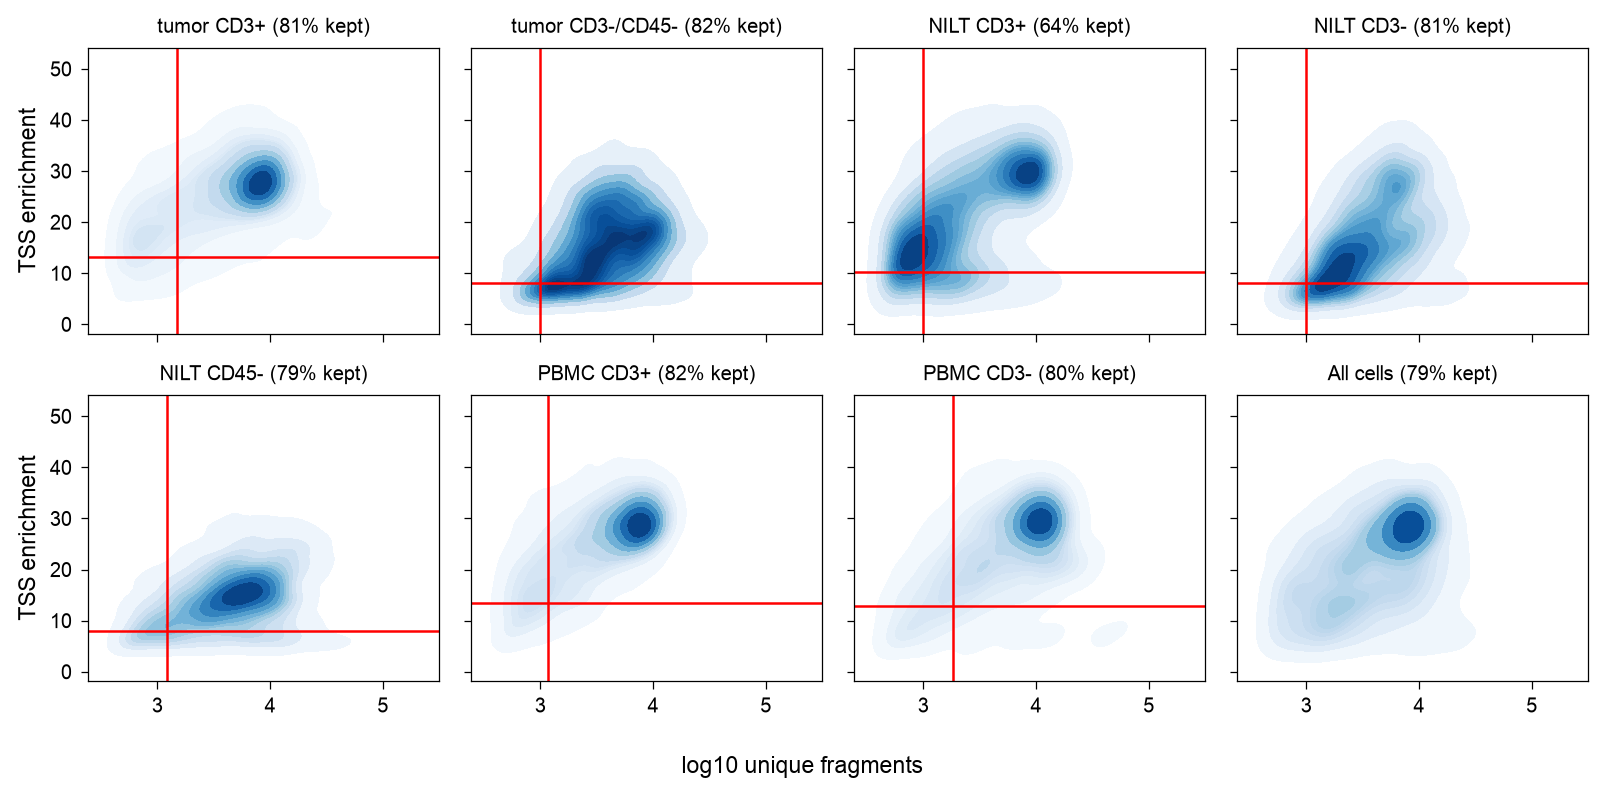

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(9, 4.4), sharex=True, sharey=True)

panels = list(SAMPLES.items()) + [('all', 'All cells')]
for ax, (gsm, name) in zip(axes.flat, panels):
    data = obs if gsm == 'all' else obs[obs['sample'] == gsm]
    kept = 100 * data['keep'].mean()

    # subsample for speed
    data = data.sample(min(len(data), 4000), random_state=0)
    sns.kdeplot(data=data, x='log_fragments', y='tsse', fill=True, cmap='Blues',
                levels=12, thresh=0.02, ax=ax)

    if gsm != 'all':
        ax.axhline(thresholds.loc[gsm, 'tsse_min'], color='red', lw=1)
        ax.axvline(np.log10(thresholds.loc[gsm, 'fragments_min']), color='red', lw=1)

    ax.set_title(f'{name} ({kept:.0f}% kept)', fontsize=8)
    ax.set_xlabel('')
    ax.set_ylabel('')

axes[0, 0].set_ylabel('TSS enrichment')
axes[1, 0].set_ylabel('TSS enrichment')
fig.supxlabel('log10 unique fragments', fontsize=9)
plt.tight_layout()
plt.show()

In [6]:
retention = pd.DataFrame({
    'cells': obs.groupby('sample').size(),
    'kept': obs.groupby('sample')['keep'].sum(),
})
retention['pct'] = (100 * retention['kept'] / retention['cells']).round(0)

pd.concat([thresholds.round(1), retention], axis=1).rename(index=SAMPLES)

,tsse_min,fragments_min,cells,kept,pct
sample,,,,,
tumor CD3+,13.1,1495.5,8621,6941,81.0
tumor CD3-/CD45-,8.0,1000.0,6281,5151,82.0
NILT CD3+,10.3,1000.0,7523,4812,64.0
NILT CD3-,8.0,1000.0,8317,6733,81.0
NILT CD45-,8.0,1209.5,8575,6808,79.0
PBMC CD3+,13.5,1172.6,19016,15525,82.0
PBMC CD3-,12.8,1848.4,8694,6953,80.0


**Reading the output.** The red lines are the thresholds of each sample, drawn on the density of its cells. They keep 79% of the cells (52,923 of 67,027), 80-82% in all samples
but NILT CD3+ (64%). That sample is the shallowest (median 1,975 fragments) and has a high median TSSE (20.6), so its relative TSSE cut (10.3) is the strictest.
Low-quality cells are mostly lost at the bottom-left corner of each panel; the dense population is untouched.

The filtered object keeps the fragments of the kept cells.

In [7]:
qc_file = OUT / 'qc_filtered.h5ad'
qc_file.unlink(missing_ok=True)

keep_idx = np.flatnonzero(obs['keep'].values)
loose.subset(obs_indices=[int(i) for i in keep_idx], out=str(qc_file), inplace=False)
loose.close()

adata = snap.read(qc_file)
cells = list(adata.obs_names)
meta = obs.loc[cells]
print(f'{adata.n_obs:,} cells kept')

52,923 cells kept


## 2. Tiles, spectral embedding, UMAP

As in the tutorial: a 500-bp tile matrix, the 250,000 most informative bins, a spectral embedding and a UMAP.
The first spectral component follows sequencing depth, so we leave it out of the UMAP.

In [8]:
tiles = snap.pp.add_tile_matrix(adata, bin_size=500, inplace=False,
                                file=str(OUT / 'tiles.h5ad'))


def embed(tile_data):
    # features -> spectral embedding -> UMAP, without the depth-driven first component
    snap.pp.select_features(tile_data, n_features=250_000)
    snap.tl.spectral(tile_data, n_comps=30)
    Z = np.asarray(tile_data.obsm['X_spectral'])
    snap.tl.umap(tile_data, use_dims=list(range(1, Z.shape[1])))
    return Z


Z1 = embed(tiles)

In [9]:
tiles.obs['tissue'] = list(meta['tissue'])
snap.pl.umap(tiles, color='tissue', sample_size=15000, width=520, height=420)

## 3. Broad lineages from gene activity

`snap.pp.make_gene_matrix` gives the gene activity (insertions in the gene body and 2 kb upstream).
A cell has only a few thousand fragments, so each marker is **smoothed** over the cell's 30 nearest
neighbours (twice) and z-scored. Each cell scores the canonical markers of the paper
(T, NK, B, plasma, myeloid, epithelial, endothelial, fibroblast) and takes its best lineage,
if the top score is above 0.5 and leads the second by more than 0.5.

In [10]:
# marker genes of each signature
SIGNATURES = {
    'T': ['CD3D', 'CD3E', 'CD3G', 'CD2'],
    'NK': ['KLRD1', 'NCR1', 'GNLY', 'KLRF1'],
    'B': ['MS4A1', 'PAX5', 'CD79A'],
    'Plasma': ['TNFRSF17', 'VOPP1'],
    'Myeloid': ['CD14', 'LYZ', 'CD163', 'APOC1', 'CST3'],
    'Epithelial': ['EPCAM', 'KRT18'],
    'Endothelial': ['VWF', 'PLVAP', 'CLDN5'],
    'Fibroblast': ['COL1A2', 'FBLN1'],
}
LINEAGE_OF = {
    'T': 'T/NK',
    'NK': 'T/NK',
    'B': 'B/plasma',
    'Plasma': 'B/plasma',
    'Myeloid': 'Myeloid',
    'Epithelial': 'Non-immune',
    'Endothelial': 'Non-immune',
    'Fibroblast': 'Non-immune',
}

# markers shown in the bubble plots: a few specific genes per cell type, in this order
# (TP63, TP73, FBLN1 and PLVAP are left out: their activity is high in several unrelated cell types)
DOT_GROUPS = [
    ('T cell', ['CD3D', 'CD3E']),
    ('CD8 T', ['CD8A', 'CD8B']),
    ('CD4 T', ['IL7R', 'IL2RA', 'CTLA4']),
    ('naive/CM', ['TCF7', 'SELL', 'CCR7']),
    ('NK', ['NCR1', 'KLRF1', 'GNLY', 'GZMB']),
    ('B', ['MS4A1', 'CD79A', 'PAX5']),
    ('Plasma', ['TNFRSF17']),
    ('Mast', ['TPSAB1']),
    ('Epithelium', ['EPCAM', 'KRT8', 'CDH1']),
    ('AT2', ['SFTPC', 'SFTPB', 'LAMP3']),
    ('Basal', ['KRT5', 'KRT17', 'KRT15']),
    ('Secretory', ['SCGB1A1', 'MUC5B', 'BPIFB1']),
    ('Ciliated', ['FOXJ1', 'CAPS', 'CCDC78']),
    ('Fibroblast', ['COL1A2', 'DCN', 'LUM']),
    ('Endothelial', ['CLDN5', 'PECAM1']),
]
# a few more genes, only used to inspect the islands in section 4
INSPECT = [('Myeloid', ['CD14', 'LYZ', 'FCGR3A', 'C1QA', 'CLEC9A', 'CD1C'])]

# marker panels of the paper for the epithelial cell types
PANELS = {
    'AT2': ['SFTPC', 'SFTPB', 'SFTPD', 'NAPSA', 'LAMP3'],
    'Basal': ['KRT5', 'KRT17', 'KRT15', 'TP63', 'MIR205HG'],
    'Secretory': ['SCGB1A1', 'SCGB3A1', 'MUC5B', 'BPIFB1'],
    'Ciliated': ['FOXJ1', 'TP73', 'CCDC78', 'CAPS'],
}

GENES = []
for names in list(SIGNATURES.values()) + [g for _, g in DOT_GROUPS + INSPECT] + list(PANELS.values()):
    GENES += [name for name in names if name not in GENES]

In [11]:
gene = snap.pp.make_gene_matrix(adata, snap.genome.hg38)   # cells x genes, a regular AnnData
sc.pp.normalize_total(gene, target_sum=1e4)
sc.pp.log1p(gene)

gene = gene[:, GENES].copy()
M = gene.X.toarray().astype(np.float32)

In [12]:
def smooth_z(M, Z, k=30, rounds=2):
    # average each cell with its k nearest neighbours in the embedding, then z-score
    neighbours = NearestNeighbors(n_neighbors=k).fit(Z[:, 1:])
    index = neighbours.kneighbors(Z[:, 1:], return_distance=False)
    for _ in range(rounds):
        M = M[index].mean(axis=1)
    return (M - M.mean(axis=0)) / (M.std(axis=0) + 1e-9)


def assign_lineage(z):
    # best lineage per cell, 'unassigned' if the call is not clear
    scores = {}
    for name, genes in SIGNATURES.items():
        columns = [GENES.index(g) for g in genes]
        scores[name] = z[:, columns].mean(axis=1)
    scores = pd.DataFrame(scores)

    lineages = {}
    for lineage in ['T/NK', 'B/plasma', 'Myeloid', 'Non-immune']:
        members = [name for name in SIGNATURES if LINEAGE_OF[name] == lineage]
        lineages[lineage] = scores[members].max(axis=1)
    lineages = pd.DataFrame(lineages)

    ranked = np.sort(lineages.values, axis=1)
    clear = (ranked[:, -1] > 0.5) & (ranked[:, -1] - ranked[:, -2] > 0.5)
    return np.where(clear, lineages.idxmax(axis=1), 'unassigned')

In [13]:
def bubble_plot(adata, groupby, rows, gene_groups, labels, figsize):
    # color: mean z of the smoothed gene activity, size: % of cells with insertions
    genes = [g for _, names in gene_groups for g in names]
    columns = [GENES.index(g) for g in genes]
    X = adata.X.toarray()
    z = adata.layers['z']

    records = []
    for y, row in enumerate(rows):
        mask = (adata.obs[groupby] == row).values
        mean_z = z[mask][:, columns].mean(axis=0)
        percent = 100 * (X[mask][:, columns] > 0).mean(axis=0)
        for x in range(len(genes)):
            records.append({'x': x, 'y': y, 'z': mean_z[x], 'percent': percent[x]})
    data = pd.DataFrame(records)

    # dot area saturates at 50% of cells, so small percentages stay readable
    size_range = (4, 110)
    fig, ax = plt.subplots(figsize=figsize)
    sns.scatterplot(data=data, x='x', y='y', size='percent', hue='z', palette='RdBu_r',
                    hue_norm=(-1.5, 1.5), size_norm=(0, 50), sizes=size_range,
                    edgecolor='0.25', linewidth=0.4, legend=False, ax=ax)
    ax.set_xticks(range(len(genes)))
    ax.set_xticklabels(genes, rotation=90, fontsize=7)
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels([labels[row] for row in rows], fontsize=8)
    ax.set_xlim(-0.7, len(genes) - 0.3)
    ax.set_ylim(len(rows) - 0.3, -0.7)
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.tick_params(length=2)

    # cell type of each group of genes, above the plot
    start = 0
    for name, names in gene_groups:
        ax.axvline(start - 0.5, color='0.85', lw=0.6)
        ax.text(start + (len(names) - 1) / 2, -0.9, name, rotation=90, ha='center',
                va='bottom', fontsize=7)
        start += len(names)

    # legends, stacked to the right of the plot
    fig.subplots_adjust(right=0.88)
    cax = fig.add_axes([0.915, 0.55, 0.015, 0.25])
    colorbar = mpl.cm.ScalarMappable(mpl.colors.Normalize(-1.5, 1.5), 'RdBu_r')
    fig.colorbar(colorbar, cax=cax, ticks=[-1, 0, 1])
    cax.set_title('mean z', fontsize=8)

    values = [5, 20, 50]
    handles = [Line2D([], [], ls='', marker='o', mfc='0.8', mec='0.25', mew=0.4,
                      ms=np.sqrt(size_range[0] + (size_range[1] - size_range[0]) * v / 50))
               for v in values]
    labels_size = [f'{v}%' if v < 50 else '50+%' for v in values]
    fig.legend(handles, labels_size, title='% cells', frameon=False, loc='upper left',
               bbox_to_anchor=(0.895, 0.45), labelspacing=1.0, handletextpad=1.0, fontsize=8,
               title_fontsize=8)
    plt.show()

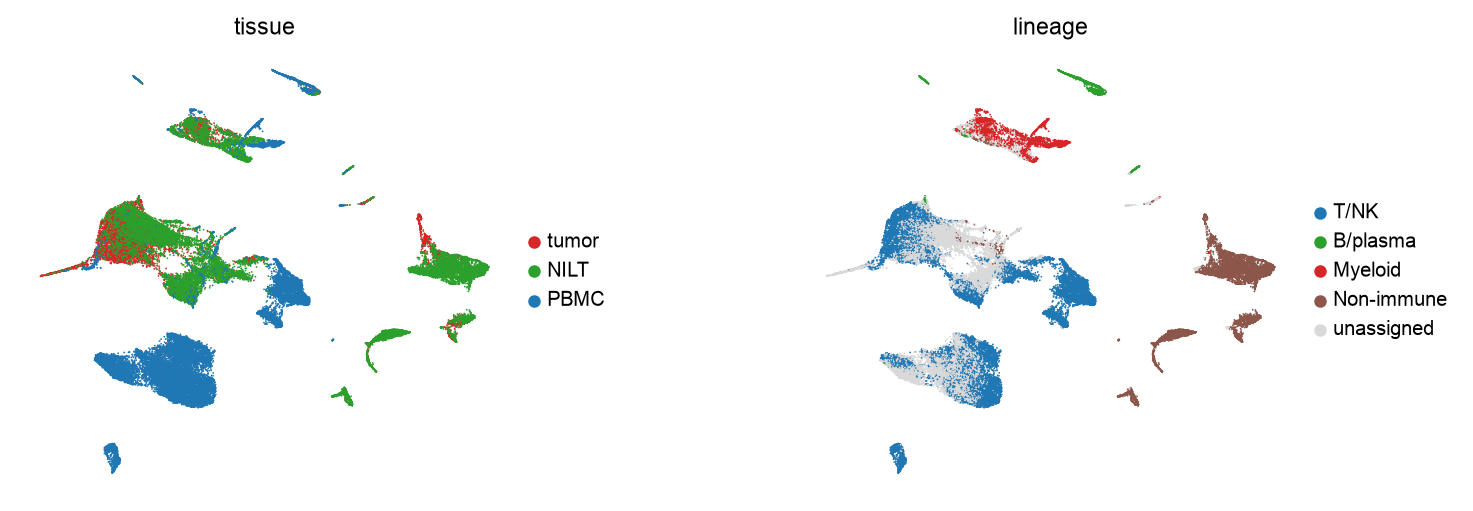

In [14]:
gene.layers['z'] = smooth_z(M, Z1)
gene.obs['tissue'] = meta['tissue'].values
gene.obs['sample'] = meta['sample'].values
gene.obs['lineage'] = assign_lineage(gene.layers['z'])
gene.obsm['X_umap'] = np.asarray(tiles.obsm['X_umap'])

set_colors(gene, 'tissue', PALETTE)
set_colors(gene, 'lineage', PALETTE)
sc.pl.umap(gene, color=['tissue', 'lineage'], size=2, wspace=0.45)

About a third of the cells stay **unassigned**: mostly shallow cells between the islands
(T cells have a weak CD3 signal at low depth). We remove them. This cleans the picture
but biases the kept cells toward deeper ones.

## 4. Re-embed the assigned cells, find the islands

We recompute the embedding on the assigned cells and cut it into **islands** (Leiden, resolution 0.3).
The profile table and the bubble plot tell us what each island is.

In [15]:
def run_leiden(adata, resolution, key, renumber=True):
    sc.pp.neighbors(adata, n_neighbors=30, use_rep='X_sp', random_state=0)
    sc.tl.leiden(adata, resolution=resolution, key_added=key, flavor='igraph',
                 n_iterations=2, directed=False, random_state=0)
    labels = adata.obs[key].astype(int)
    if renumber:
        # island 0 is the biggest
        order = {old: new for new, old in enumerate(labels.value_counts().index)}
        labels = labels.map(order)
    categories = [str(i) for i in sorted(labels.unique())]
    adata.obs[key] = pd.Categorical(labels.astype(str), categories=categories)

In [16]:
assigned = np.flatnonzero(gene.obs['lineage'] != 'unassigned')

tiles2 = tiles.subset(obs_indices=[int(i) for i in assigned],
                      out=str(OUT / 'tiles_assigned.h5ad'), inplace=False)
Z2 = embed(tiles2)

g2 = gene[assigned].copy()
g2.obsm['X_umap'] = np.asarray(tiles2.obsm['X_umap'])
g2.obsm['X_sp'] = Z2[:, 1:]
g2.layers['z'] = smooth_z(M[assigned], Z2)
run_leiden(g2, 0.3, 'island')

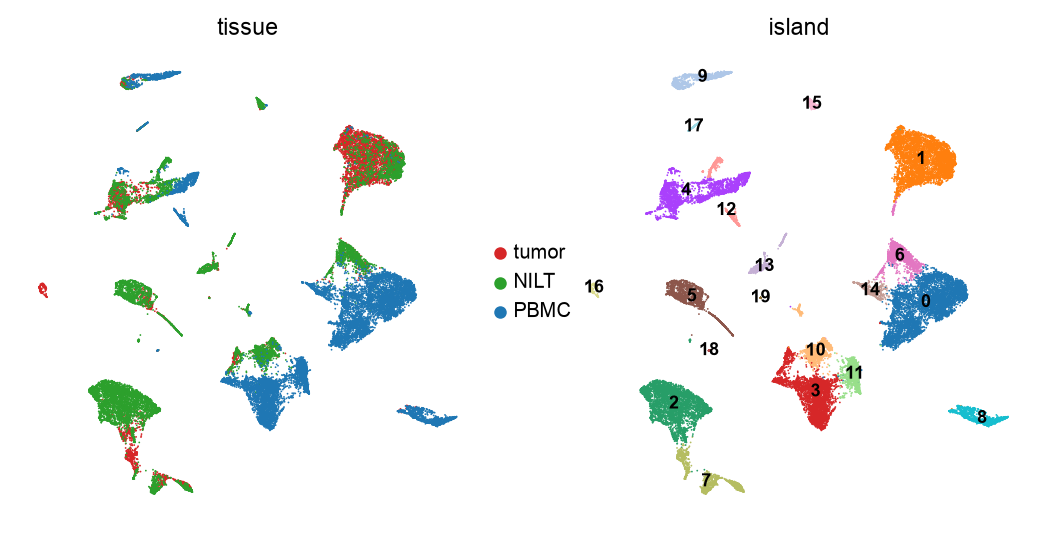

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.4))
sc.pl.umap(g2, color='tissue', size=2, ax=axes[0], show=False)
sc.pl.umap(g2, color='island', size=2, legend_loc='on data', legend_fontsize=7,
           ax=axes[1], show=False)
plt.show()

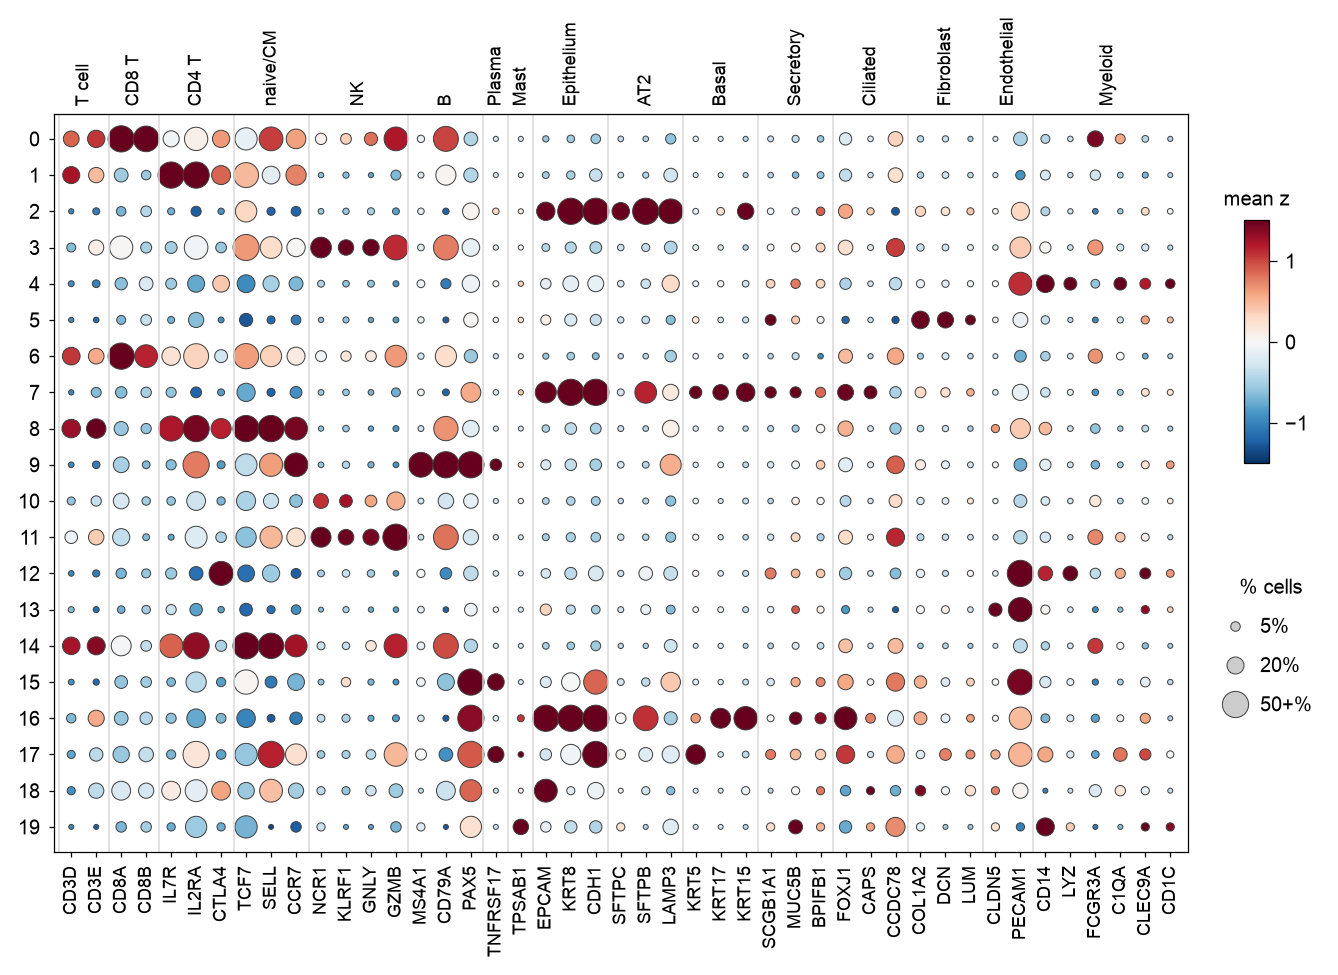

In [18]:
islands = list(g2.obs['island'].cat.categories)
bubble_plot(g2, 'island', islands, DOT_GROUPS + INSPECT, {i: i for i in islands}, (9, 5.4))

In [19]:
rows = []
for island, data in g2.obs.groupby('island', observed=True):
    mask = (g2.obs['island'] == island).values
    mean_z = pd.Series(g2.layers['z'][mask].mean(axis=0), index=GENES)
    lineage = data['lineage'].value_counts(normalize=True)
    tissue = data['tissue'].value_counts(normalize=True)

    rows.append({
        'island': island,
        'cells': len(data),
        'lineage': lineage.index[0],
        'purity': round(lineage.iloc[0], 2),
        'tissue': ', '.join(f'{t} {100 * v:.0f}%' for t, v in tissue.items() if v >= 0.1),
        'top markers': ', '.join(f'{g} {v:.1f}' for g, v in mean_z.nlargest(4).items()),
    })

profile = pd.DataFrame(rows).set_index('island')
profile

,cells,lineage,purity,tissue,top markers
island,,,,,
0,6074,T/NK,1.00,PBMC 98%,"CD8B 1.9, CD8A 1.8, FCGR3A 1.4, GZMB 1.2"
1,5236,T/NK,0.99,"tumor 78%, NILT 22%","IL7R 1.9, IL2RA 1.5, CD2 1.4, CD3G 1.3"
2,4180,Non-immune,0.99,NILT 91%,"SFTPC 2.3, SFTPB 2.3, LAMP3 2.3, NAPSA 2.2"
3,3633,T/NK,1.00,PBMC 89%,"NCR1 2.1, GNLY 1.6, KLRF1 1.6, GZMB 1.1"
4,2893,Myeloid,0.95,"NILT 40%, tumor 33%, PBMC 27%","CD14 2.5, LYZ 2.4, CD163 2.2, CD1C 2.1"
5,1790,Non-immune,1.00,"NILT 76%, tumor 24%","COL1A2 3.7, FBLN1 3.5, DCN 3.5, LUM 2.8"
6,1380,T/NK,1.00,"NILT 75%, tumor 21%","CD8A 1.5, KLRD1 1.5, CD8B 1.2, CD3D 1.1"
7,1376,Non-immune,1.00,"tumor 54%, NILT 46%","CAPS 3.9, MIR205HG 3.8, KRT17 3.1, EPCAM 2.5"
8,1361,T/NK,1.00,PBMC 98%,"SELL 2.1, TCF7 1.9, CD3E 1.9, IL2RA 1.4"


**Curation.** Most islands are one population with the composition expected from the sort design.
Four are not and are removed:

* **4**: 2,893 cells from all tissues that mix CD14, LYZ, CD1C and C1QA (several myeloid states in one island)
* **12**: LYZ together with CD4, CTLA4 and CLEC9A, which we cannot read
* **17**: plasma (TNFRSF17) mixed with KRT5, probably doublets or ambient signal
* **18**: 32 cells, mixed

Island 7 (epithelium with an endothelial-like component) is heterogeneous but kept.
The other islands are named from their markers and sample composition.

## 5. Final embedding, clusters, cell types

We re-embed the remaining cells once more and cluster them (Leiden, resolution 0.5, which splits the
islands without mixing them). Each cluster takes the name of the island that provides most of its cells.
The three epithelial islands are only called 'Epithelium' for now: a few markers cannot tell the
epithelial cell types apart, so they are resolved in the next step.

In [20]:
DROP = [4, 12, 17, 18]
NAMES = {
    0: 'CD8 T effector',
    1: 'CD4 T / Treg-like',
    2: 'Epithelium',
    3: 'NK',
    5: 'Fibroblasts',
    6: 'CD8 T',
    7: 'Epithelium',
    8: 'CD4 T naive/CM',
    9: 'B cells',
    10: 'NK',
    11: 'NK cytotoxic',
    13: 'Endothelial',
    14: 'T naive/CM',
    15: 'Plasma cells',
    16: 'Epithelium',
    19: 'Mast cells',
}

# stop if the island numbering changed: DROP and NAMES would no longer match
islands = set(range(g2.obs['island'].nunique()))
assert islands - set(DROP) == set(NAMES), 'island numbering changed, update DROP and NAMES'

keep = ~g2.obs['island'].astype(int).isin(DROP).values

In [21]:
tiles3 = tiles2.subset(obs_indices=[int(i) for i in np.flatnonzero(keep)],
                       out=str(OUT / 'tiles_final.h5ad'), inplace=False)
Z3 = embed(tiles3)

g3 = g2[keep].copy()
g3.obsm['X_umap'] = np.asarray(tiles3.obsm['X_umap'])
g3.obsm['X_sp'] = Z3[:, 1:]
g3.layers['z'] = smooth_z(M[assigned][keep], Z3)
run_leiden(g3, 0.5, 'cluster', renumber=False)

final_idx = assigned[keep]
print(f'{g3.n_obs:,} cells kept ({len(assigned) - g3.n_obs:,} removed with the doubtful islands)')

30,807 cells kept (3,898 removed with the doubtful islands)


In [22]:
rows = []
for cluster, data in g3.obs.groupby('cluster', observed=True):
    island = int(data['island'].value_counts().index[0])
    tissue = data['tissue'].value_counts(normalize=True)
    rows.append({
        'cluster': cluster,
        'cells': len(data),
        'fine_type': NAMES[island],
        'tissue': tissue.index[0] if tissue.iloc[0] >= 0.7 else 'mixed',
    })

clusters = pd.DataFrame(rows).set_index('cluster')

**Epithelial cell types.** Each epithelial cluster is scored with the paper's marker panels
(AT2, basal, secretory, ciliated; mean z of the panel genes). A cluster gets the best panel
if it leads the second by at least 1, otherwise it is named after the two best panels.
Clusters with fewer than 100 cells are left unresolved.

In [23]:
z = pd.DataFrame(g3.layers['z'], columns=GENES, index=g3.obs_names)

scores = {}
for cluster in clusters.index[clusters['fine_type'] == 'Epithelium']:
    cluster_mean = z[(g3.obs['cluster'] == cluster).values].mean()
    scores[cluster] = {panel: cluster_mean[genes].mean() for panel, genes in PANELS.items()}
scores = pd.DataFrame(scores).T


def epithelial_type(panel_scores, n_cells):
    ranked = panel_scores.sort_values(ascending=False)
    if n_cells < 100:
        return 'Epithelium (unresolved)'
    if ranked.iloc[0] - ranked.iloc[1] < 1:
        return f'Epithelium ({ranked.index[0].lower()}/{ranked.index[1].lower()})'
    return f'{ranked.index[0]} epithelium'


for cluster, panel_scores in scores.iterrows():
    clusters.loc[cluster, 'fine_type'] = epithelial_type(panel_scores, clusters.loc[cluster, 'cells'])

scores.round(1).join(clusters[['cells', 'tissue', 'fine_type']])

,AT2,Basal,Secretory,Ciliated,cells,tissue,fine_type
5,-0.4,1.2,0.2,3.3,364,mixed,Ciliated epithelium
8,0.6,2.0,2.9,0.9,536,mixed,Epithelium (secretory/basal)
12,0.1,3.9,0.4,1.3,502,tumor,Basal epithelium
13,0.5,2.3,1.0,1.5,205,tumor,Epithelium (basal/ciliated)
16,2.1,0.7,0.6,0.0,4126,NILT,AT2 epithelium
17,0.4,0.4,1.3,-0.5,48,NILT,Epithelium (unresolved)


In [24]:
epithelial_types = sorted(t for t in clusters['fine_type'].unique() if 'pithelium' in t)
FINE_TYPES = [
    'CD8 T effector', 'CD8 T', 'CD4 T / Treg-like', 'CD4 T naive/CM', 'T naive/CM', 'NK',
    'NK cytotoxic', 'B cells', 'Plasma cells', 'Mast cells',
] + epithelial_types + ['Fibroblasts', 'Endothelial']

LINEAGE_OF_TYPE = {}
for name in FINE_TYPES:
    if name in epithelial_types or name in ['Fibroblasts', 'Endothelial']:
        LINEAGE_OF_TYPE[name] = 'Non-immune'
    elif name in ['B cells', 'Plasma cells']:
        LINEAGE_OF_TYPE[name] = 'B/plasma'
    elif name == 'Mast cells':
        LINEAGE_OF_TYPE[name] = 'Myeloid'
    else:
        LINEAGE_OF_TYPE[name] = 'T/NK'

clusters['lineage'] = clusters['fine_type'].map(LINEAGE_OF_TYPE)
clusters['order'] = clusters['fine_type'].map(FINE_TYPES.index)
clusters = clusters.sort_values(['order', 'cells'], ascending=[True, False]).drop(columns='order')
clusters

,cells,fine_type,tissue,lineage
cluster,,,,
3,3708,CD8 T effector,PBMC,T/NK
4,2371,CD8 T effector,PBMC,T/NK
2,1382,CD8 T,NILT,T/NK
0,5219,CD4 T / Treg-like,tumor,T/NK
1,1376,CD4 T naive/CM,PBMC,T/NK
11,695,T naive/CM,PBMC,T/NK
10,2966,NK,PBMC,T/NK
9,1305,NK,NILT,T/NK
15,669,NK,mixed,T/NK


## 6. Do the markers support the cell types?

Gene activity is a summary, raw accessibility is more direct. We compute the **pseudobulk coverage**
of every cell type around its marker genes (the function behind `snap.pl.coverage`).
A marker supports its cell type if the marker's promoter (TSS -2 kb to +1 kb) is among the top 3 cell types
and at least 1.4x (log2 >= 0.5) the median of the other cell types.

In [25]:
MARKERS = {
    'CD8 T effector': ['CD8A', 'CD8B', 'GZMB', 'PRF1'],
    'CD8 T': ['CD8A', 'CD8B', 'KLRD1'],
    'CD4 T / Treg-like': ['IL7R', 'IL2RA', 'CTLA4', 'CD4'],
    'CD4 T naive/CM': ['TCF7', 'SELL', 'CCR7', 'CD4'],
    'T naive/CM': ['TCF7', 'SELL', 'CCR7'],
    'NK': ['NCR1', 'KLRF1', 'GNLY', 'KLRD1'],
    'NK cytotoxic': ['GZMB', 'PRF1', 'NCR1', 'KLRF1'],
    'B cells': ['MS4A1', 'CD79A', 'PAX5'],
    'Plasma cells': ['TNFRSF17'],
    'Mast cells': ['TPSAB1'],
    'AT2 epithelium': ['SFTPC', 'SFTPB', 'LAMP3'],
    'Basal epithelium': ['KRT5', 'KRT17', 'KRT15'],
    'Secretory epithelium': ['SCGB1A1', 'MUC5B', 'BPIFB1'],
    'Ciliated epithelium': ['FOXJ1', 'CAPS', 'CCDC78'],
    'Fibroblasts': ['COL1A2', 'DCN', 'LUM'],
    'Endothelial': ['CLDN5', 'PECAM1'],
}
# only the cell types found in the data (types named after two panels have no marker set)
MARKERS = {t: genes for t, genes in MARKERS.items() if t in set(clusters['fine_type'])}
wanted = {g for genes in MARKERS.values() for g in genes}
wanted |= {'CD8A', 'NCR1', 'MS4A1', 'SFTPC', 'KRT17', 'FOXJ1', 'SCGB1A1'}   # genes shown below

# gene coordinates from the annotation used by snapATAC2
coordinates = {}
with gzip.open(snap.genome.hg38.annotation, 'rt') as handle:
    for line in handle:
        fields = line.split('\t')
        if line[0] == '#' or fields[2] != 'gene':
            continue
        match = re.search(r'gene_name=([^;]+)', fields[8])
        if match and match.group(1) in wanted:
            coordinates[match.group(1)] = (fields[0], int(fields[3]), int(fields[4]), fields[6])

In [26]:
def window(gene_name):
    # region of at most 80 kb: 10 kb upstream of the TSS to the end of the gene
    chrom, start, end, strand = coordinates[gene_name]
    if strand == '+':
        return chrom, start - 10000, min(end + 3000, start + 70000), start, strand
    return chrom, max(start - 3000, end - 70000), end + 10000, end, strand


# label every cell with its cell type (cells not in the final set are 'excluded')
labels = np.array(['excluded'] * adata.n_obs, dtype=object)
labels[final_idx] = g3.obs['cluster'].map(clusters['fine_type']).astype(str).values


def compute_coverage():
    coverage = {}
    for name in sorted(coordinates):
        chrom, lo, hi, tss, strand = window(name)
        result = snap_internal.get_coverage(adata, f'{chrom}:{lo}-{hi}', list(labels))
        coverage[name] = {t: np.asarray(v, float) for t, v in result.items() if t != 'excluded'}
    return coverage


cache = OUT / 'coverage.pkl'
if cache.exists():
    COV = pickle.load(open(cache, 'rb'))
else:
    COV = compute_coverage()
    pickle.dump(COV, open(cache, 'wb'))

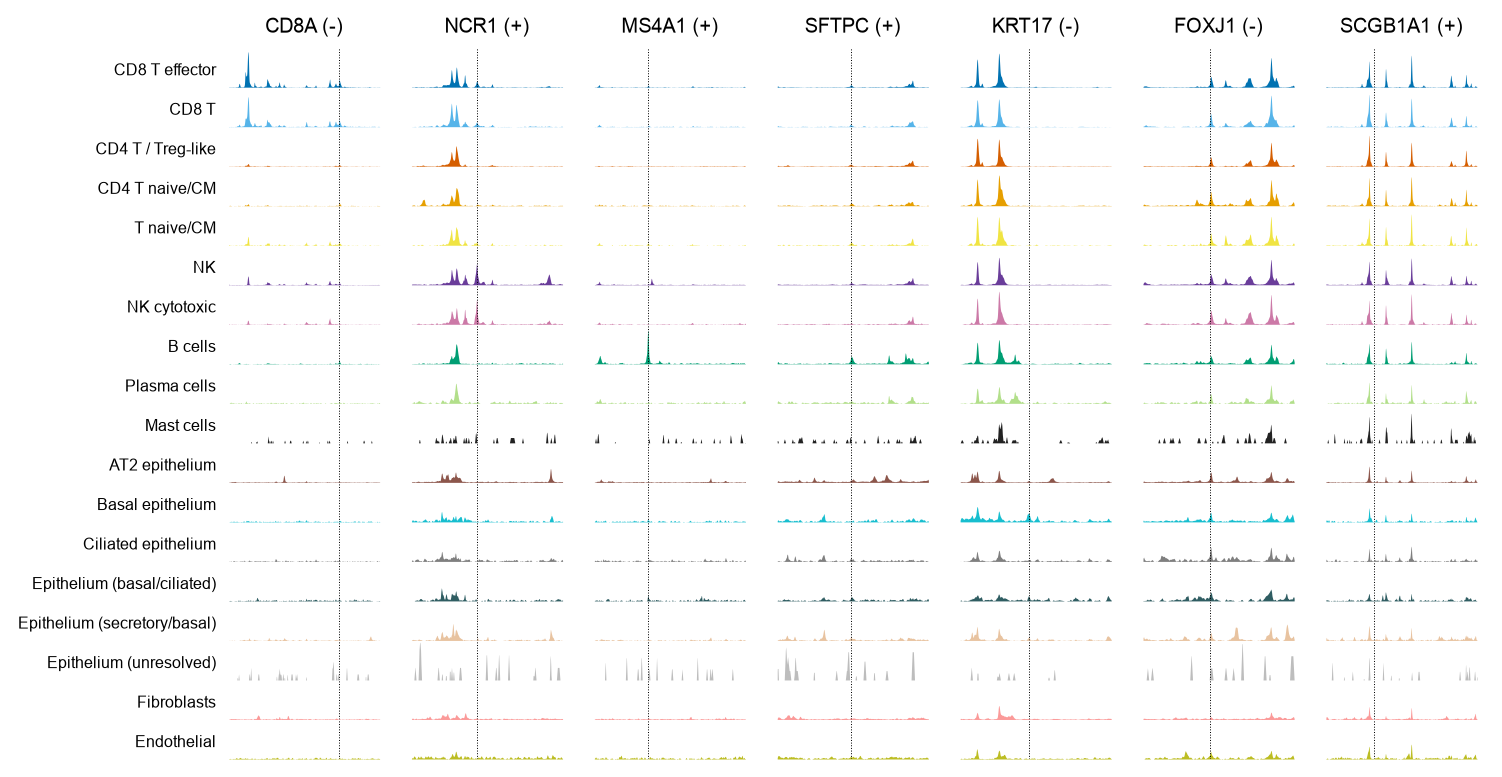

In [27]:
TYPE_COLORS = {
    'CD8 T effector': '#0072B2', 'CD8 T': '#56B4E9', 'CD4 T / Treg-like': '#D55E00',
    'CD4 T naive/CM': '#E69F00', 'T naive/CM': '#F0E442', 'NK': '#6A3D9A',
    'NK cytotoxic': '#CC79A7', 'B cells': '#009E73', 'Plasma cells': '#B2DF8A',
    'Mast cells': '#222222', 'AT2 epithelium': '#8C564B', 'Basal epithelium': '#17BECF',
    'Ciliated epithelium': '#7F7F7F', 'Secretory epithelium': '#C49C94',
    'Epithelium (secretory/basal)': '#E8C3A0', 'Epithelium (basal/ciliated)': '#2F5D62',
    'Epithelium (unresolved)': '#BDBDBD', 'Fibroblasts': '#FB9A99', 'Endothelial': '#BCBD22',
}
types = [t for t in FINE_TYPES if t in COV['CD8A']]
shown = ['CD8A', 'NCR1', 'MS4A1', 'SFTPC', 'KRT17', 'FOXJ1', 'SCGB1A1']

fig, axes = plt.subplots(len(types), len(shown), figsize=(9, 5.2), sharex='col',
                         gridspec_kw={'hspace': 0, 'wspace': 0.1})
for j, name in enumerate(shown):
    chrom, lo, hi, tss, strand = window(name)
    ymax = max(COV[name][t].max() for t in types) * 1.05

    for i, cell_type in enumerate(types):
        ax = axes[i, j]
        track = np.convolve(COV[name][cell_type], np.ones(150) / 150, mode='same')
        x = np.linspace(lo, hi, len(track))
        ax.fill_between(x, 0, track, color=TYPE_COLORS[cell_type], lw=0)
        ax.axvline(tss, color='k', lw=0.4, ls=':')
        ax.set_ylim(0, ymax)
        ax.axis('off')
        if j == 0:
            ax.text(-0.03, 0.3, cell_type, transform=ax.transAxes, ha='right', fontsize=6.5)

    axes[0, j].set_title(f'{name} ({strand})', fontsize=8)
plt.show()

In [28]:
def promoter_coverage(name):
    # coverage in the promoter window (TSS -2 kb to +1 kb) of each cell type
    chrom, lo, hi, tss, strand = window(name)
    start, end = (tss - 2000, tss + 1000) if strand == '+' else (tss - 1000, tss + 2000)
    totals = {}
    for cell_type, track in COV[name].items():
        first = int((start - lo) / (hi - lo) * len(track))
        last = int((end - lo) / (hi - lo) * len(track))
        totals[cell_type] = track[first:last].sum()
    return pd.Series(totals)


rows = []
for cell_type, markers in MARKERS.items():
    for name in markers:
        coverage = promoter_coverage(name)
        others = coverage.drop(cell_type).median()
        rows.append({
            'cell_type': cell_type,
            'marker': name,
            'log2_fold': np.log2((coverage[cell_type] + 0.01) / (others + 0.01)),
            'rank': int(coverage.rank(ascending=False)[cell_type]),
        })

support = pd.DataFrame(rows)
support['supported'] = (support['rank'] <= 3) & (support['log2_fold'] >= 0.5)

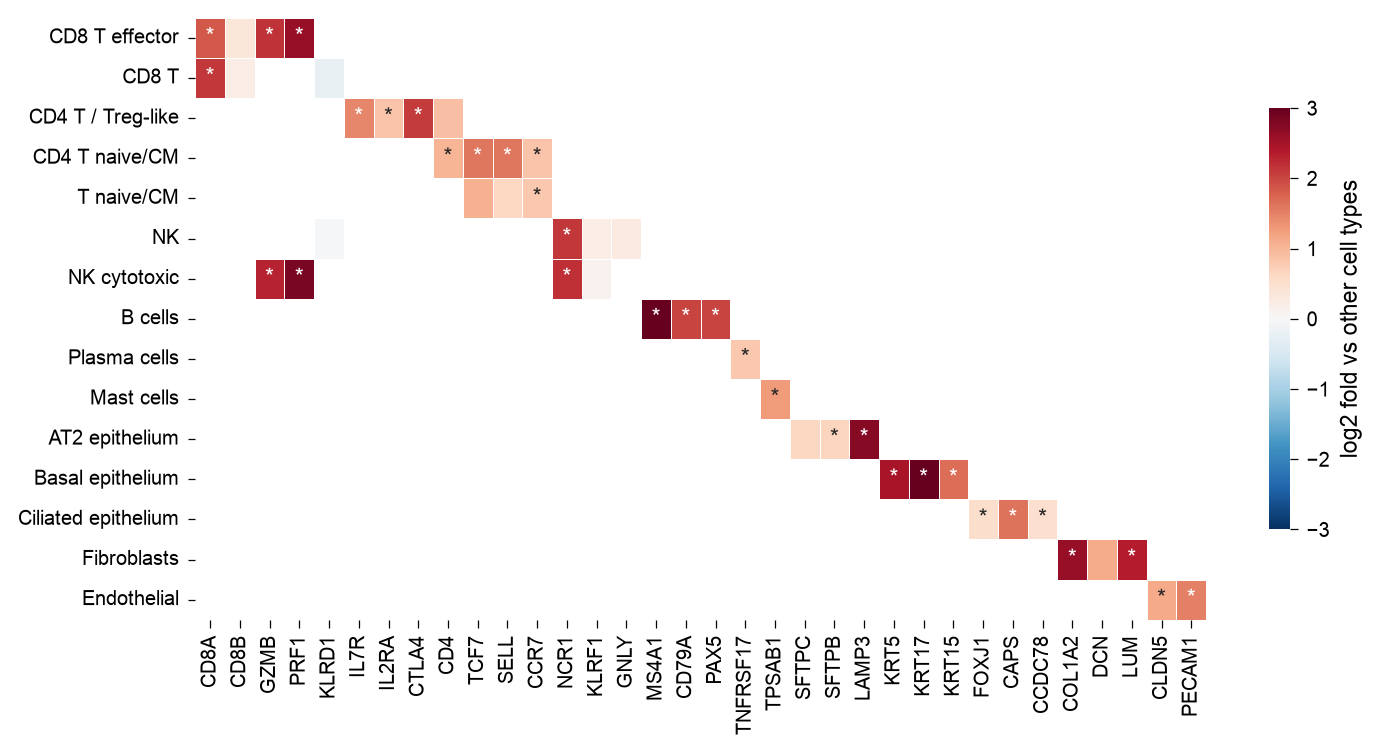

In [29]:
marker_order = list(dict.fromkeys(support['marker']))
fold = support.pivot(index='cell_type', columns='marker', values='log2_fold')
fold = fold.reindex(index=list(MARKERS), columns=marker_order)

# a star marks a supported marker
stars = support.pivot(index='cell_type', columns='marker', values='supported')
stars = stars.reindex(index=list(MARKERS), columns=marker_order)
stars = stars.fillna(False).astype(bool).map(lambda x: '*' if x else '')

plt.figure(figsize=(9, 4.4))
sns.heatmap(fold, mask=fold.isna(), cmap='RdBu_r', center=0, vmin=-3, vmax=3,
            annot=stars, fmt='', linewidths=0.4, linecolor='white',
            cbar_kws={'label': 'log2 fold vs other cell types', 'shrink': 0.7})
plt.xlabel('')
plt.ylabel('')
plt.xticks(rotation=90)
plt.show()

In [30]:
summary = support.groupby('cell_type', sort=False).agg(
    markers=('marker', ', '.join),
    supported=('supported', 'sum'),
    of=('supported', 'size'),
)
summary['cells'] = pd.Series(labels).value_counts()
summary['verdict'] = np.where(summary['supported'] / summary['of'] < 0.5,
                              'unsupported: merge', 'supported')
summary

,markers,supported,of,cells,verdict
cell_type,,,,,
CD8 T effector,"CD8A, CD8B, GZMB, PRF1",3,4,6079,supported
CD8 T,"CD8A, CD8B, KLRD1",1,3,1382,unsupported: merge
CD4 T / Treg-like,"IL7R, IL2RA, CTLA4, CD4",3,4,5219,supported
CD4 T naive/CM,"TCF7, SELL, CCR7, CD4",4,4,1376,supported
T naive/CM,"TCF7, SELL, CCR7",1,3,695,unsupported: merge
NK,"NCR1, KLRF1, GNLY, KLRD1",1,4,4940,unsupported: merge
NK cytotoxic,"GZMB, PRF1, NCR1, KLRF1",3,4,1212,supported
B cells,"MS4A1, CD79A, PAX5",3,3,1289,supported
Plasma cells,TNFRSF17,1,1,288,supported


**Merge.** CD8 T (NILT), T naive/CM and NK are supported by fewer than half of their markers.
Each shares its markers with a supported sub-type, so we merge them:

* CD8 T effector + CD8 T -> **CD8 T**
* CD4 T naive/CM + T naive/CM -> **T naive/CM**
* NK cytotoxic + NK -> **NK**

Types with one or two markers (plasma, mast, endothelial) have thin evidence.
Unsupported types without a closest supported type are kept and flagged, not merged.

In [31]:
unsupported = set(summary.index[summary['verdict'].str.startswith('unsupported')])
print('unsupported but not merged:', sorted(unsupported - {'CD8 T', 'T naive/CM', 'NK'}))
unsupported = unsupported & {'CD8 T', 'T naive/CM', 'NK'}

# unsupported type -> its closest supported type
CLOSEST = {'CD8 T': 'CD8 T effector', 'T naive/CM': 'CD4 T naive/CM', 'NK': 'NK cytotoxic'}

MERGE = {}
for name in unsupported:
    MERGE[name] = name
    MERGE[CLOSEST[name]] = name

clusters['cell_type'] = clusters['fine_type'].map(lambda t: MERGE.get(t, t))
g3.obs['cell_type'] = g3.obs['cluster'].map(clusters['cell_type']).astype(str).values
g3.obs['lineage'] = g3.obs['cluster'].map(clusters['lineage']).astype(str).values

print({old: new for old, new in MERGE.items() if old != new})
g3.obs['cell_type'].value_counts().rename('cells').to_frame().T

unsupported but not merged: []
{'CD8 T effector': 'CD8 T', 'NK cytotoxic': 'NK', 'CD4 T naive/CM': 'T naive/CM'}


cell_type,CD8 T,NK,CD4 T / Treg-like,AT2 epithelium,T naive/CM,Fibroblasts,B cells,Endothelial,Epithelium (secretory/basal),Basal epithelium,Ciliated epithelium,Plasma cells,Epithelium (basal/ciliated),Epithelium (unresolved),Mast cells
cells,7461,6152,5219,4126,2071,1792,1289,723,536,502,364,288,205,48,31


## 7. Final result

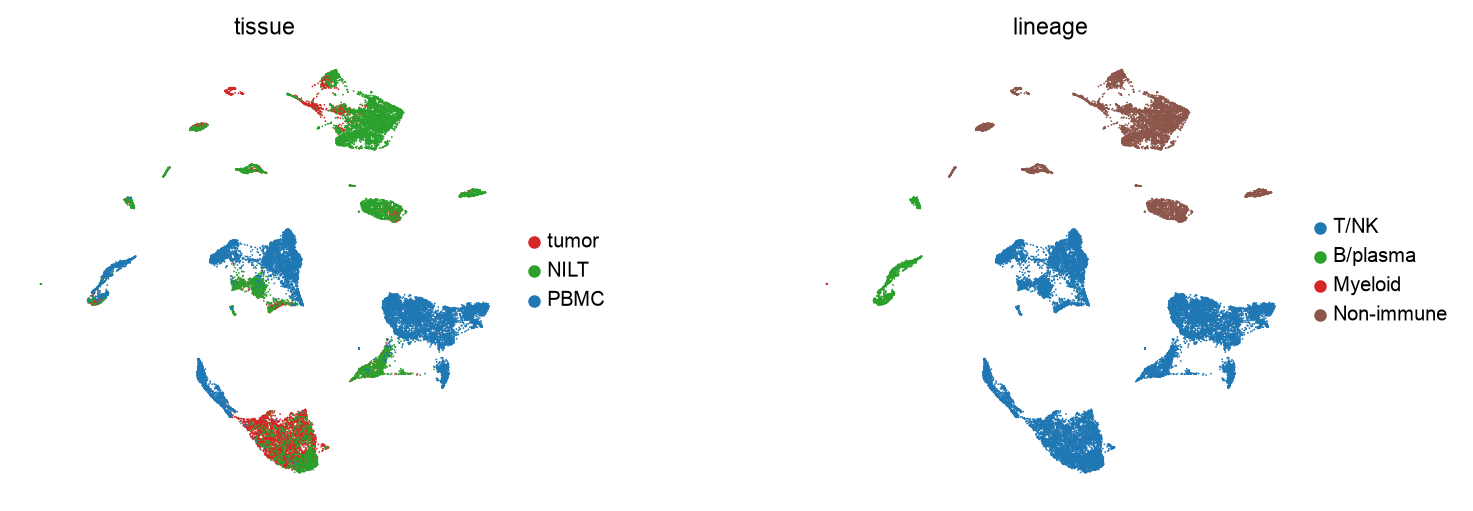

In [32]:
PALETTE.update(TYPE_COLORS)
set_colors(g3, 'tissue', PALETTE)
set_colors(g3, 'lineage', PALETTE)
set_colors(g3, 'cell_type', PALETTE)

sc.pl.umap(g3, color=['tissue', 'lineage'], size=2, wspace=0.45)

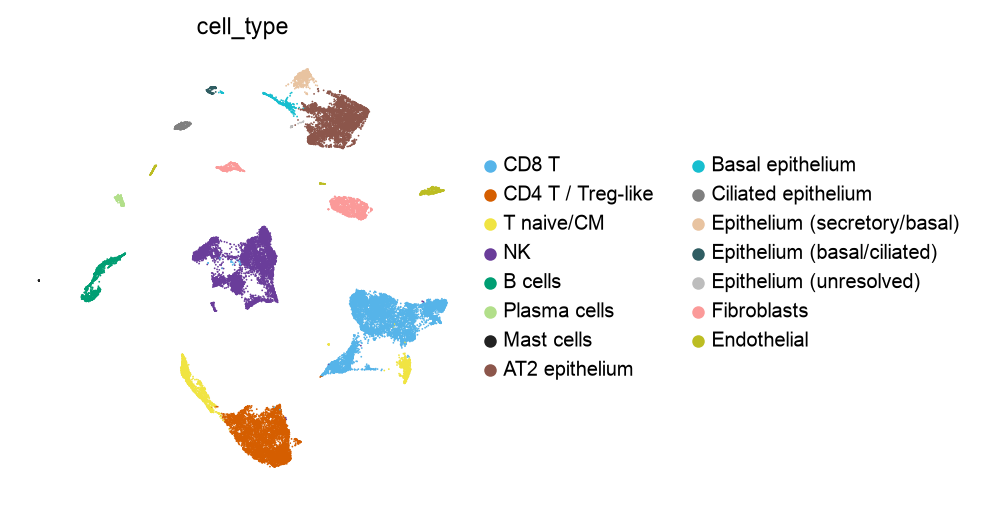

In [33]:
sc.pl.umap(g3, color='cell_type', size=2)

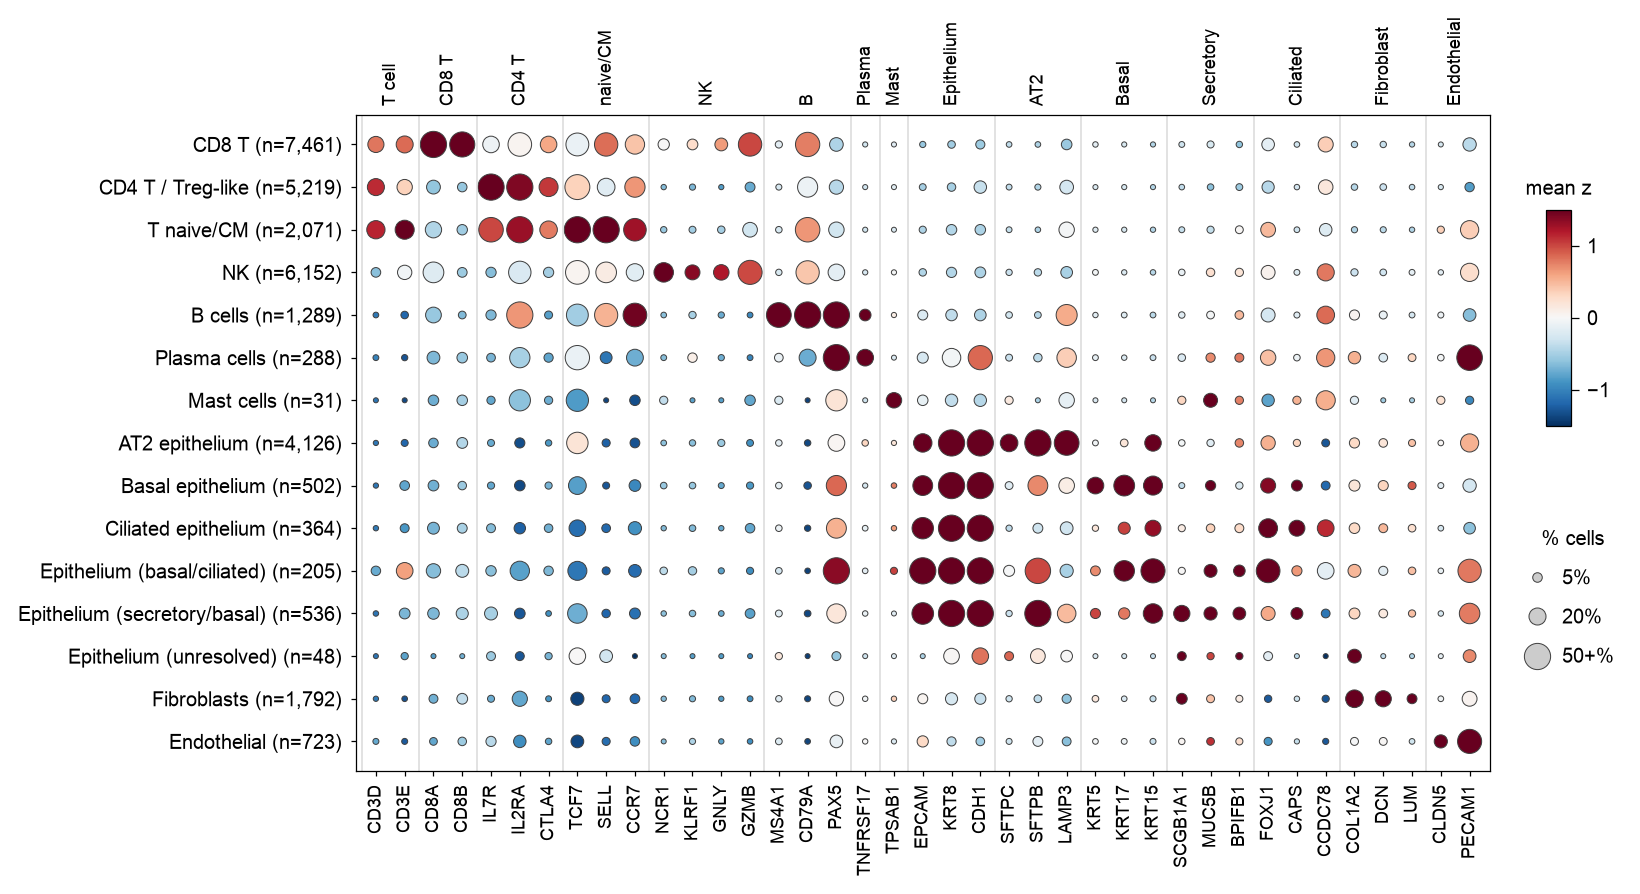

In [34]:
final_types = list(dict.fromkeys(MERGE.get(t, t) for t in FINE_TYPES if t in set(clusters['fine_type'])))
counts = g3.obs['cell_type'].value_counts()
labels_final = {t: f'{t} (n={counts[t]:,})' for t in final_types}

bubble_plot(g3, 'cell_type', final_types, DOT_GROUPS, labels_final, (9, 4.8))

Abundance of each cell type in each sample (% of the cells kept from the sample).
The cell types follow the sort design: T cells in the CD3+ samples, NK in the CD3- samples,
epithelium and fibroblasts in the CD45- and tumor fractions.

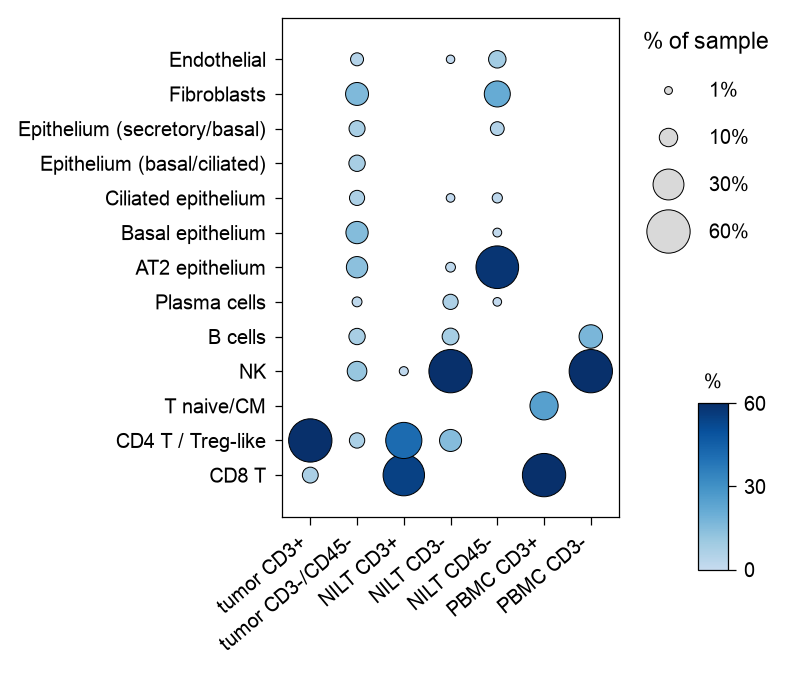

In [35]:
counts = pd.crosstab(g3.obs['cell_type'], g3.obs['sample'].map(SAMPLES))
percent = 100 * counts / counts.sum()
percent = percent.stack().rename('percent').reset_index()
percent.columns = ['cell_type', 'sample', 'percent']
percent = percent[percent['percent'] >= 1]

type_order = [t for t in final_types if t in set(percent['cell_type'])]
percent['cell_type'] = pd.Categorical(percent['cell_type'], categories=type_order)
percent['sample'] = pd.Categorical(percent['sample'], categories=list(SAMPLES.values()))

# one colour scale and one size scale, drawn as a colorbar and a size legend
cmap = LinearSegmentedColormap.from_list('blues', plt.cm.Blues(np.linspace(0.25, 1, 256)))

fig, ax = plt.subplots(figsize=(5.5, 4.2))
sns.scatterplot(data=percent, x='sample', y='cell_type', size='percent', hue='percent',
                palette=cmap, size_norm=(0, 60), hue_norm=(0, 60), sizes=(5, 300),
                edgecolor='k', linewidth=0.4, legend=False, ax=ax)
ax.invert_yaxis()
ax.margins(0.1)
ax.set_xlabel('')
ax.set_ylabel('')
plt.setp(ax.get_xticklabels(), rotation=40, ha='right')

values = [1, 10, 30, 60]
handles = [Line2D([], [], ls='', marker='o', mfc='0.85', mec='k', mew=0.4,
                  ms=np.sqrt(5 + 295 * v / 60)) for v in values]
ax.legend(handles, [f'{v}%' for v in values], title='% of sample', frameon=False,
          loc='upper left', bbox_to_anchor=(1.03, 1), labelspacing=1.4, handletextpad=1.8, borderpad=0.2)

cax = fig.add_axes([0.80, 0.18, 0.03, 0.22])
fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(0, 60), cmap=cmap), cax=cax, ticks=[0, 30, 60])
cax.set_title('%', fontsize=8)
fig.subplots_adjust(left=0.38, right=0.72, bottom=0.25)
plt.show()

In [36]:
annotation = g3.obs[['sample', 'tissue', 'lineage', 'cluster', 'cell_type']].copy()
annotation['fine_type'] = g3.obs['cluster'].map(clusters['fine_type']).astype(str).values
annotation['n_fragment'] = meta['n_fragment'].values[final_idx]
annotation['tsse'] = meta['tsse'].values[final_idx]
annotation[['UMAP1', 'UMAP2']] = g3.obsm['X_umap']

annotation.to_csv(OUT / 'annotation.csv')
print(f'{len(annotation):,} annotated cells saved to {OUT.name}/annotation.csv')

30,807 annotated cells saved to results/annotation.csv


## 8. Mitochondrial lineage tracing

The MT allele-frequency matrix (AFM) comes from the same cells (mtscATAC-seq). Only cells that survived the ATAC QC
**and** carry a cell type enter the MiTo pipeline, so every clone is a clone of well-characterized cells:

1. restrict the AFM to the annotated cells, then `filter1` (mean MT coverage >= 10 and below an upper bound),
2. select informative MT variants within each sample (`filter_afm`) and take the union,
3. genotype the pooled cells on the union, drop incompatible or too prevalent variants,
4. weighted-Jaccard distances, UPMGA tree, clones.

In [37]:
import anndata
import mito as mt
from mito.tl.phylo import _get_leaves_order, _get_muts_order

anndata.settings.allow_write_nullable_strings = True

afm = sc.read_h5ad(AFM_FILE)
print(f'{afm.n_obs:,} cells with MT data, {afm.n_vars:,} candidate MT variants')

funnel = {
    'cells in the loose ATAC object': len(obs),
    'pass the ATAC QC': len(cells),
    'annotated (cell type)': g3.n_obs,
}

# only ATAC-annotated cells
afm = afm[afm.obs_names.isin(g3.obs_names)].copy()
print(f'{afm.n_obs:,} of them are annotated in ATAC ({100 * afm.n_obs / g3.n_obs:.0f}% of the annotated cells)')
funnel['annotated, with MT data'] = afm.n_obs
has_mt = set(afm.obs_names)

# filter1: mean MT coverage
mt.pp.filter_cells(afm, cell_filter='filter1')
print(f'{afm.n_obs:,} cells after filter1')
funnel['MT coverage (filter1)'] = afm.n_obs
covered = set(afm.obs_names)

50,095 cells with MT data, 49,708 candidate MT variants


27,996 of them are annotated in ATAC (91% of the annotated cells)


23,378 cells after filter1


In [38]:
# informative variants of each sample, then their union
variants = {}
for sample in SAMPLES:
    cells = afm[afm.obs['sample'] == sample].copy()
    mt.pp.filter_afm(cells)
    variants[sample] = set(cells.var_names)

union = sorted(set().union(*variants.values()))
pd.Series({SAMPLES[s]: len(v) for s, v in variants.items()}, name='variants').to_frame().T.assign(union=len(union))

2026-11-02 18:32:22 - WARNING - 1602 candidate MT-SNVs: keeping the 1000 most over-dispersed (max_candidates). Raise it to test more, at a cost in time and memory.


2026-11-02 18:47:57 - WARNING - 1358 candidate MT-SNVs: keeping the 1000 most over-dispersed (max_candidates). Raise it to test more, at a cost in time and memory.


2026-11-02 18:50:16 - WARNING - 3077 candidate MT-SNVs: keeping the 1000 most over-dispersed (max_candidates). Raise it to test more, at a cost in time and memory.


2026-11-02 19:36:27 - WARNING - 2020 candidate MT-SNVs: keeping the 1000 most over-dispersed (max_candidates). Raise it to test more, at a cost in time and memory.


2026-11-02 19:37:16 - WARNING - 2834 candidate MT-SNVs: keeping the 1000 most over-dispersed (max_candidates). Raise it to test more, at a cost in time and memory.


,tumor CD3+,tumor CD3-/CD45-,NILT CD3+,NILT CD3-,NILT CD45-,PBMC CD3+,PBMC CD3-,union
variants,81,76,48,5,23,117,48,346


In [39]:
# genotype the pooled cells on the union of variants
afm = afm[:, afm.var_names.isin(union)].copy()
mt.pp.annotate_vars(afm)
mt.pp.call_genotypes(afm, alpha=1e-3)

# remove variants carried by more than half of the cells or by a single one
genotypes = afm.layers['bin'].toarray() > 0
keep = (genotypes.mean(axis=0) <= 0.5) & (genotypes.sum(axis=0) >= 2)

# remove variants called in >3% of the cells of every sample (next best: <0.3%): germline-like, not clonal
by_sample = pd.DataFrame(genotypes, columns=afm.var_names).groupby(afm.obs['sample'].values).mean()
shared = by_sample.columns[(by_sample > 0.03).all()]
print('shared across all samples (removed):', list(shared))
display(by_sample[shared].rename(index=SAMPLES).round(2).T)
keep &= ~afm.var_names.isin(shared)
afm = afm[:, keep].copy()

mt.pp.filter_incompatible_variants(afm)

# cells with at least one variant
afm = afm[(afm.layers['bin'] > 0).sum(axis=1).A1 >= 1].copy()
mt.pp.annotate_vars(afm, overwrite=True)
print(f'{afm.n_obs:,} cells x {afm.n_vars} variants')
funnel['with at least one variant (in the tree)'] = afm.n_obs

shared across all samples (removed): ['16261_C>T']


,tumor CD3+,tumor CD3-/CD45-,NILT CD3+,NILT CD3-,NILT CD45-,PBMC CD3+,PBMC CD3-
16261_C>T,0.1,0.08,0.08,0.09,0.08,0.08,0.08


4,732 cells x 345 variants


In [40]:
mt.pp.compute_distances(afm, metric='weighted_jaccard', ncores=8)
tree = mt.tl.build_tree(afm, solver='UPMGA')
mt.tl.annotate_clones(tree, afm)

afm.obs['MiTo_clone'] = afm.obs['MiTo_clone'].astype(str)
sizes = afm.obs['MiTo_clone'].value_counts().drop('unassigned', errors='ignore')
print(f'{len(sizes)} clones, {sizes.sum():,} of {afm.n_obs:,} cells assigned ({100 * sizes.sum() / afm.n_obs:.0f}%)')
sizes.head(8).to_frame().T

209 clones, 4,438 of 4,732 cells assigned (94%)


MiTo_clone,MT-1,MT-2,MT-3,MT-4,MT-5,MT-6,MT-7,MT-8
count,299,277,214,206,141,127,125,109


### Joining ATAC and MT

We put the clone of each cell next to its ATAC annotation. **Most annotated cells do not end up in the tree**, and it is worth seeing where they are lost (funnel below).
Cells without MT data are not in the AFM; cells with a low mean MT coverage (below `filter1`) cannot be genotyped; and most of the others carry none of the clonal
variants selected by `filter_afm` (called with a strict test), so there is nothing to place them with. We keep these strict defaults: relaxing them (lower coverage cut, more candidate variants, a looser genotyping
test) adds cells, but the added cells are less often assigned to a clone and the clones made of them are noisier. Cells outside the tree are labelled `no MT` in `MiTo_clone` and
by their reason in `MT_status`.

In [41]:
# one table per cell: ATAC annotation + MT clone
g3.obs['MiTo_clone'] = afm.obs['MiTo_clone'].reindex(g3.obs_names).fillna('no MT').values
g3.obs['in_tree'] = g3.obs_names.isin(afm.obs_names)

# why a cell is not in the tree
status = np.select(
    [g3.obs['in_tree'], g3.obs_names.isin(covered), g3.obs_names.isin(has_mt)],
    ['in tree', 'no informative variant', 'low MT coverage'],
    default='no MT data',
)
g3.obs['MT_status'] = pd.Categorical(status, categories=['in tree', 'no informative variant', 'low MT coverage', 'no MT data'])


# the funnel, from the loose object to the tree
display(pd.Series(funnel, name='cells').to_frame().assign(**{'% of previous': lambda d: (100 * d['cells'] / d['cells'].shift()).round(0)}))

# and, for each cell type, where the cells are lost
joint = pd.crosstab(g3.obs['cell_type'], g3.obs['MT_status'])
joint['% in tree'] = (100 * joint['in tree'] / joint.sum(axis=1)).round(1)
display(joint)

g3.write(OUT / 'atac_annotated_clones.h5ad')
afm.write(OUT / 'mt_afm.h5ad')
pickle.dump(tree, open(OUT / 'mt_tree.pkl', 'wb'))

,cells,% of previous
cells in the loose ATAC object,67027,NaN
pass the ATAC QC,52923,79.0
annotated (cell type),30807,58.0
"annotated, with MT data",27996,91.0
MT coverage (filter1),23378,84.0
with at least one variant (in the tree),4732,20.0


MT_status,in tree,no informative variant,low MT coverage,no MT data,% in tree
cell_type,,,,,
CD8 T,2250,3700,754,757,30.2
CD4 T / Treg-like,561,3528,714,416,10.7
T naive/CM,259,1492,120,200,12.5
NK,564,3823,1160,605,9.2
B cells,142,961,143,43,11.0
Plasma cells,24,202,42,20,8.3
Mast cells,2,16,8,5,6.5
AT2 epithelium,461,2425,909,331,11.2
Basal epithelium,67,237,150,48,13.3


The tree holds a minority of the annotated cells, and CD8 T cells are over-represented in it (30% of them are in the tree, against 8-13% for most other types).
Clone-level results should be read with that in mind.

**Final figure.** Left: cells x variants (binary genotypes), ordered as the tree leaves, with colour strips for
tissue, cell type and clone (grey = unassigned). Middle: the tree of all cells, clones collapsed.
Right: the tree of the clones with more than 20 cells, rebuilt on them.

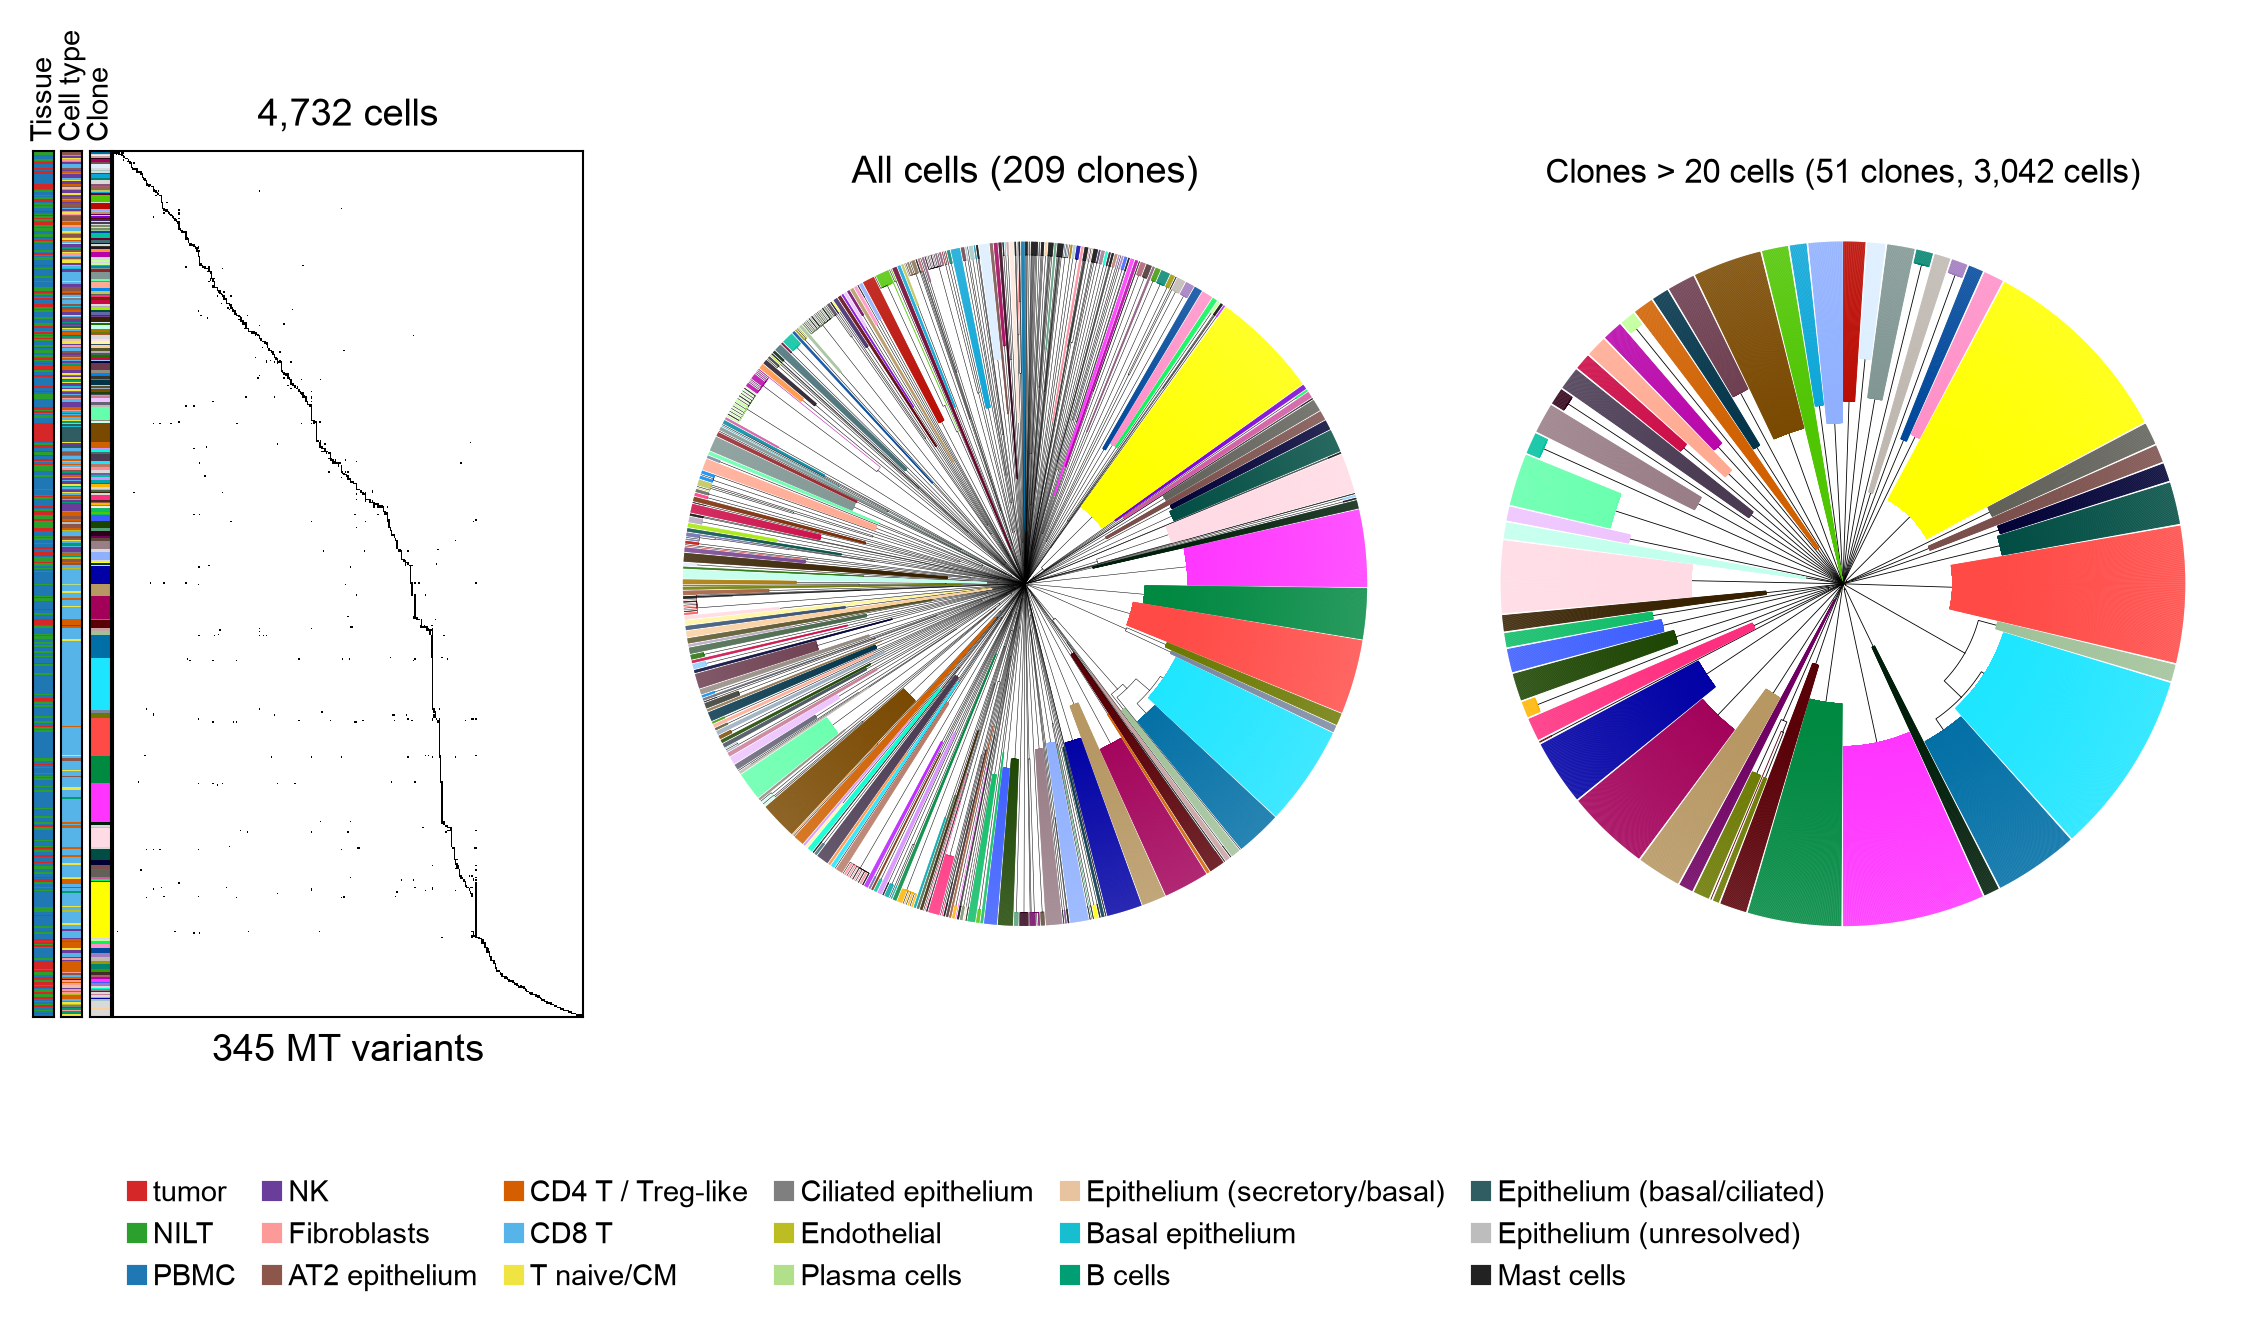

In [42]:
MIN_CELLS = 20

# one colour per clone, largest clones first
clone_colors = {clone: sc.pl.palettes.godsnot_102[i % 102] for i, clone in enumerate(sizes.index)}
clone_colors['unassigned'] = '#d9d9d9'

cell_type = g3.obs['cell_type'].astype(str)
tissue = g3.obs['tissue'].astype(str)

# tree of the large clones only
large = sizes.index[sizes > MIN_CELLS]
afm_large = afm[afm.obs['MiTo_clone'].isin(large)].copy()
tree_large = mt.tl.build_tree(afm_large, solver='UPMGA')

for t, a in [(tree, afm), (tree_large, afm_large)]:
    t.cell_meta['MiTo_clone'] = a.obs['MiTo_clone'].reindex(t.cell_meta.index)


def plot_collapsed(tree, ax, linewidth):
    mt.pl.plot_tree(tree, ax=ax, collapse_clones='MiTo_clone', clone_style='full', gap_by='MiTo_clone',
                    cmaps={'MiTo_clone': clone_colors},
                    branches=dict(annot='MiTo_clone', linewidth=linewidth))
    ax.set_aspect('equal')


order = _get_leaves_order(tree)
variants_order = _get_muts_order(tree)
genotypes = (afm[order, variants_order].layers['bin'].toarray() > 0).astype(float)

# rows pooled (max) so that the thin marks of small clones survive the rendering
pool = int(np.ceil(len(order) / 600))
genotypes = np.pad(genotypes, ((0, -len(genotypes) % pool), (0, 0))).reshape(-1, pool, genotypes.shape[1]).max(axis=1)
rows = np.arange(0, len(order), pool)[:len(genotypes)]
strips = {
    'Tissue': tissue.loc[order].iloc[rows].map(PALETTE),
    'Cell type': cell_type.loc[order].iloc[rows].map(PALETTE),
    'Clone': afm.obs.loc[order, 'MiTo_clone'].iloc[rows].map(clone_colors),
}

fig = plt.figure(figsize=(9, 3.8), dpi=150)
grid = fig.add_gridspec(1, 3, width_ratios=[1.25, 2, 2], wspace=0.1)
axes = [fig.add_subplot(grid[0, j]) for j in range(3)]

axes[0].imshow(genotypes, cmap='Greys', vmin=0, vmax=1, aspect='auto', interpolation='nearest')
axes[0].set(xticks=[], yticks=[], xlabel=f'{afm.n_vars} MT variants')
axes[0].set_title(f'{afm.n_obs:,} cells', fontsize=9)

for i, (name, colors) in enumerate(strips.items()):
    strip = axes[0].inset_axes((-0.05 * (3 - i) - 0.01 * (2 - i), 0, 0.045, 1))
    strip.imshow(np.arange(len(colors))[:, None], cmap=mpl.colors.ListedColormap(list(colors)),
                 aspect='auto', interpolation='nearest')
    strip.set(xticks=[], yticks=[])
    strip.text(0.5, 1.01, name, rotation=90, ha='center', va='bottom', fontsize=7, transform=strip.transAxes)

plot_collapsed(tree, axes[1], 0.12)
plot_collapsed(tree_large, axes[2], 0.2)
axes[1].set_title(f'All cells ({len(sizes)} clones)', fontsize=9)
axes[2].set_title(f'Clones > {MIN_CELLS} cells ({len(large)} clones, {afm_large.n_obs:,} cells)', fontsize=8)

handles = [Line2D([], [], marker='s', ls='', color=PALETTE[t], label=t) for t in ['tumor', 'NILT', 'PBMC']]
handles += [Line2D([], [], marker='s', ls='', color=PALETTE[c], label=c)
            for c in cell_type.loc[order].unique() if c in PALETTE]
fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, 0.03), ncol=6, frameon=False,
           fontsize=7, columnspacing=1.0, handletextpad=0.3)
plt.show()

## 9. Clones enriched in specific cell types

For every clone with more than 20 cells and every cell type, a one-sided Fisher's exact test asks whether the clone holds
more cells of that type than expected from the cells in the tree (2 x 2 table: in / out of the clone, of the type / not).
P-values are corrected for the number of tests (Benjamini-Hochberg). Clones are then ranked by significance within each cell type.
Cell types are tied to the sort design (CD3+, CD3-, CD45-), so an enrichment says where a clone sits, not that the clone is lineage-restricted.

In [43]:
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests

MIN_CELLS = 20
labels = afm.obs['MiTo_clone'].astype(str)
types = g3.obs['cell_type'].astype(str).reindex(afm.obs_names)
clones_big = sizes.index[sizes > MIN_CELLS]
types_tested = types.value_counts()[lambda s: s >= MIN_CELLS].index

rows = []
for clone in clones_big:
    in_clone = (labels == clone).values
    for ct in types_tested:
        is_type = (types == ct).values
        a = (in_clone & is_type).sum()
        b = (in_clone & ~is_type).sum()
        c = (~in_clone & is_type).sum()
        d = (~in_clone & ~is_type).sum()
        odds, p = fisher_exact([[a, b], [c, d]], alternative='greater')
        rows.append(dict(clone=clone, cell_type=ct, n_clone=a + b, n_type_in_clone=a, expected=(a + b) * (a + c) / (a + b + c + d), p=p))

enrich = pd.DataFrame(rows)
enrich['fdr'] = multipletests(enrich['p'], method='fdr_bh')[1]
enrich['fold'] = enrich['n_type_in_clone'] / enrich['expected']
enrich['-log10 p'] = -np.log10(enrich['p'].clip(lower=1e-300))
enrich.to_csv(OUT / 'clone_celltype_enrichment.csv', index=False)

hits = enrich[(enrich['fdr'] < 0.05) & (enrich['n_type_in_clone'] >= 3)].sort_values('p')
print(f'{len(clones_big)} clones > {MIN_CELLS} cells x {len(types_tested)} cell types = {len(enrich)} tests; '
      f'{len(hits)} enrichments at FDR < 0.05 in {hits["clone"].nunique()} clones')
hits[['clone', 'cell_type', 'n_clone', 'n_type_in_clone', 'fold', 'fdr']].head(15).round(4)

51 clones > 20 cells x 13 cell types = 663 tests; 48 enrichments at FDR < 0.05 in 44 clones


,clone,cell_type,n_clone,n_type_in_clone,fold,fdr
111,MT-9,Epithelium (basal/ciliated),103,77,36.8491,0.0
13,MT-2,CD8 T,277,272,2.0651,0.0
0,MT-1,CD8 T,299,276,1.9413,0.0
26,MT-3,CD8 T,214,206,2.0245,0.0
39,MT-4,CD8 T,206,194,1.9806,0.0
65,MT-6,CD8 T,127,126,2.0866,0.0
237,MT-19,AT2 epithelium,41,39,9.7639,0.0
78,MT-7,CD8 T,125,120,2.0190,0.0
91,MT-8,CD8 T,109,102,1.9680,0.0
197,MT-16,CD4 T / Treg-like,43,34,6.6695,0.0


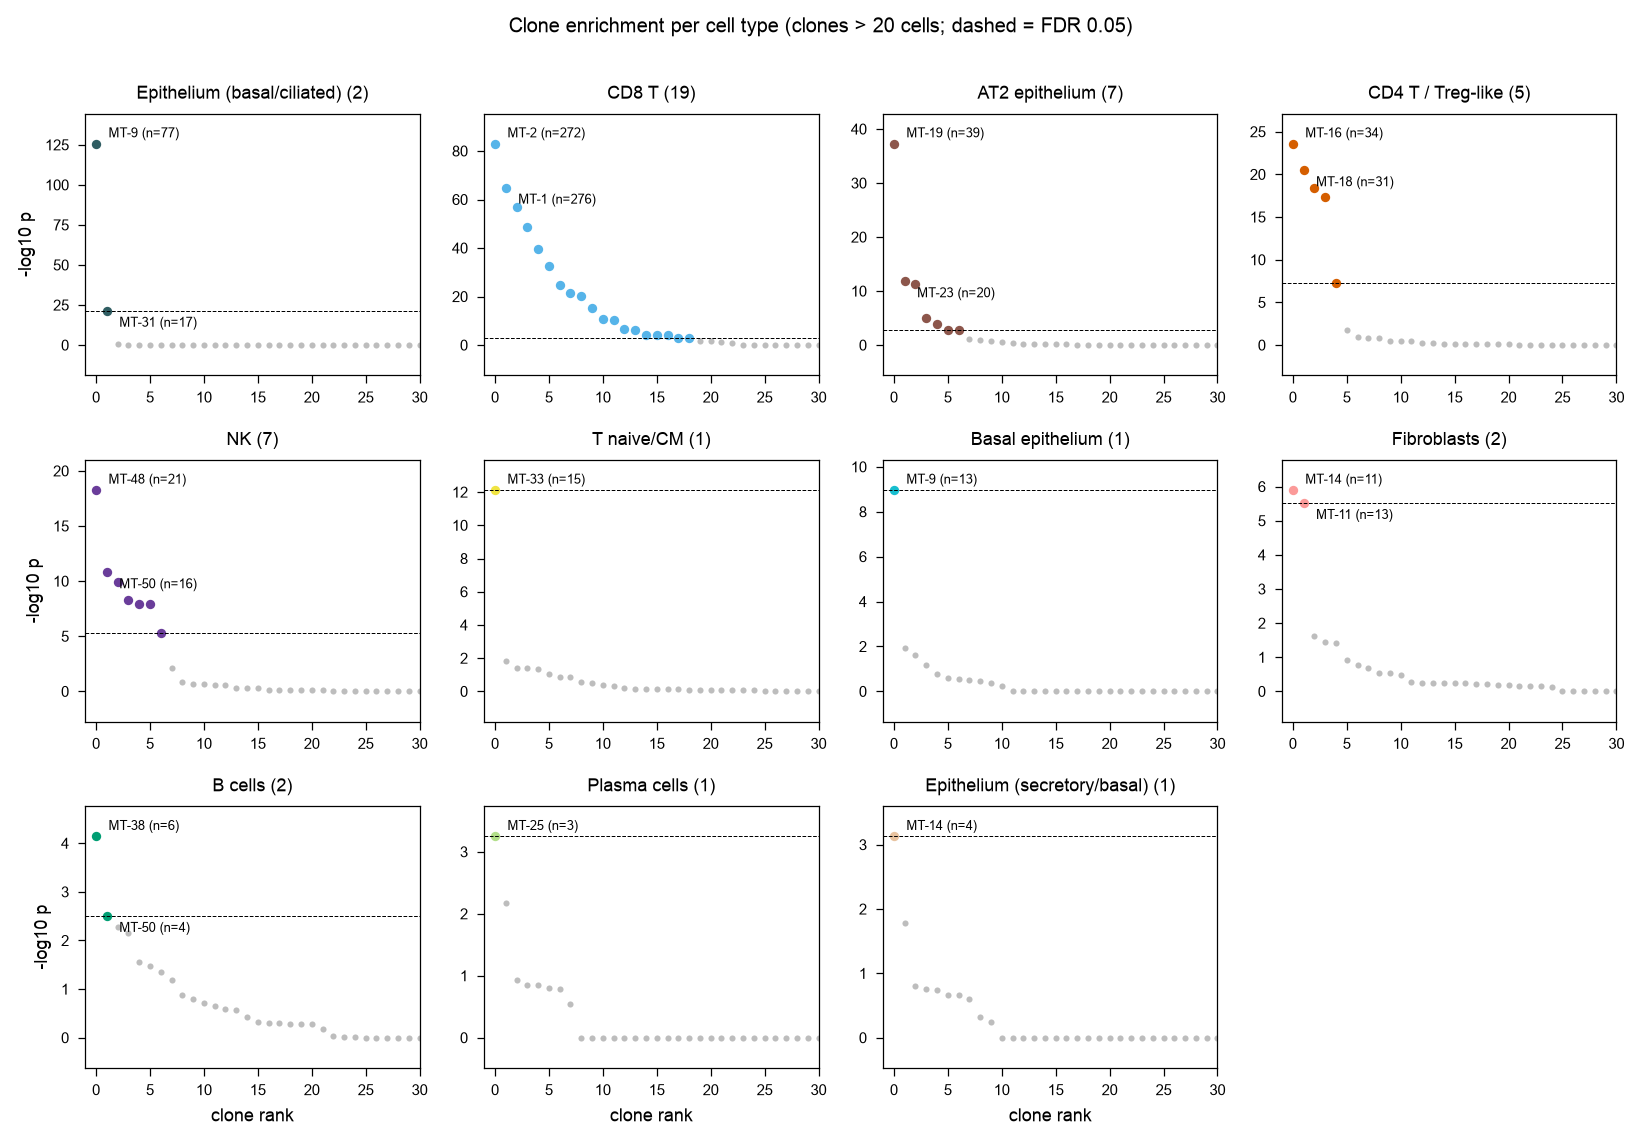

In [44]:
# rank plot: clones ordered by significance, one panel per cell type with at least one enrichment
panels = list(hits['cell_type'].drop_duplicates())
ncols = min(4, len(panels))
nrows = int(np.ceil(len(panels) / ncols))
fig, axs = plt.subplots(nrows, ncols, figsize=(2.3 * ncols, 2.1 * nrows), squeeze=False)

for ax, ct in zip(axs.flat, panels):
    d = enrich[enrich['cell_type'] == ct].sort_values('p').reset_index(drop=True)
    hit = (d['fdr'] < 0.05) & (d['n_type_in_clone'] >= 3)
    ax.scatter(d.index[~hit], d['-log10 p'][~hit], s=6, color='#bdbdbd', lw=0)
    ax.scatter(d.index[hit], d['-log10 p'][hit], s=14, color=PALETTE.get(ct, 'tab:red'), lw=0)
    for k, i in enumerate(d.index[hit][:2]):
        ax.annotate(f"{d.loc[i, 'clone']} (n={d.loc[i, 'n_type_in_clone']})", (i, d.loc[i, '-log10 p']),
                    xytext=(5, 4 - 9 * k), textcoords='offset points', fontsize=5, va='center')
    ax.axhline(-np.log10(d.loc[hit, 'p'].max()) if hit.any() else 0, color='k', lw=0.4, ls='--')
    ax.set_title(f'{ct} ({hit.sum()})', fontsize=7)
    ax.tick_params(labelsize=6)
    ax.set_xlim(-1, 30)
    ax.margins(y=0.15)

for ax in axs.flat[len(panels):]:
    ax.axis('off')
for ax in axs[-1]:
    ax.set_xlabel('clone rank', fontsize=7)
for ax in axs[:, 0]:
    ax.set_ylabel('-log10 p', fontsize=7)
fig.suptitle(f'Clone enrichment per cell type (clones > {MIN_CELLS} cells; dashed = FDR 0.05)', fontsize=8, y=1.0)
fig.tight_layout()
plt.show()

### Representative enriched clones on the UMAP

The most significant clone of each cell type (at least 15 cells of the type), shown on the ATAC UMAP of all annotated cells.

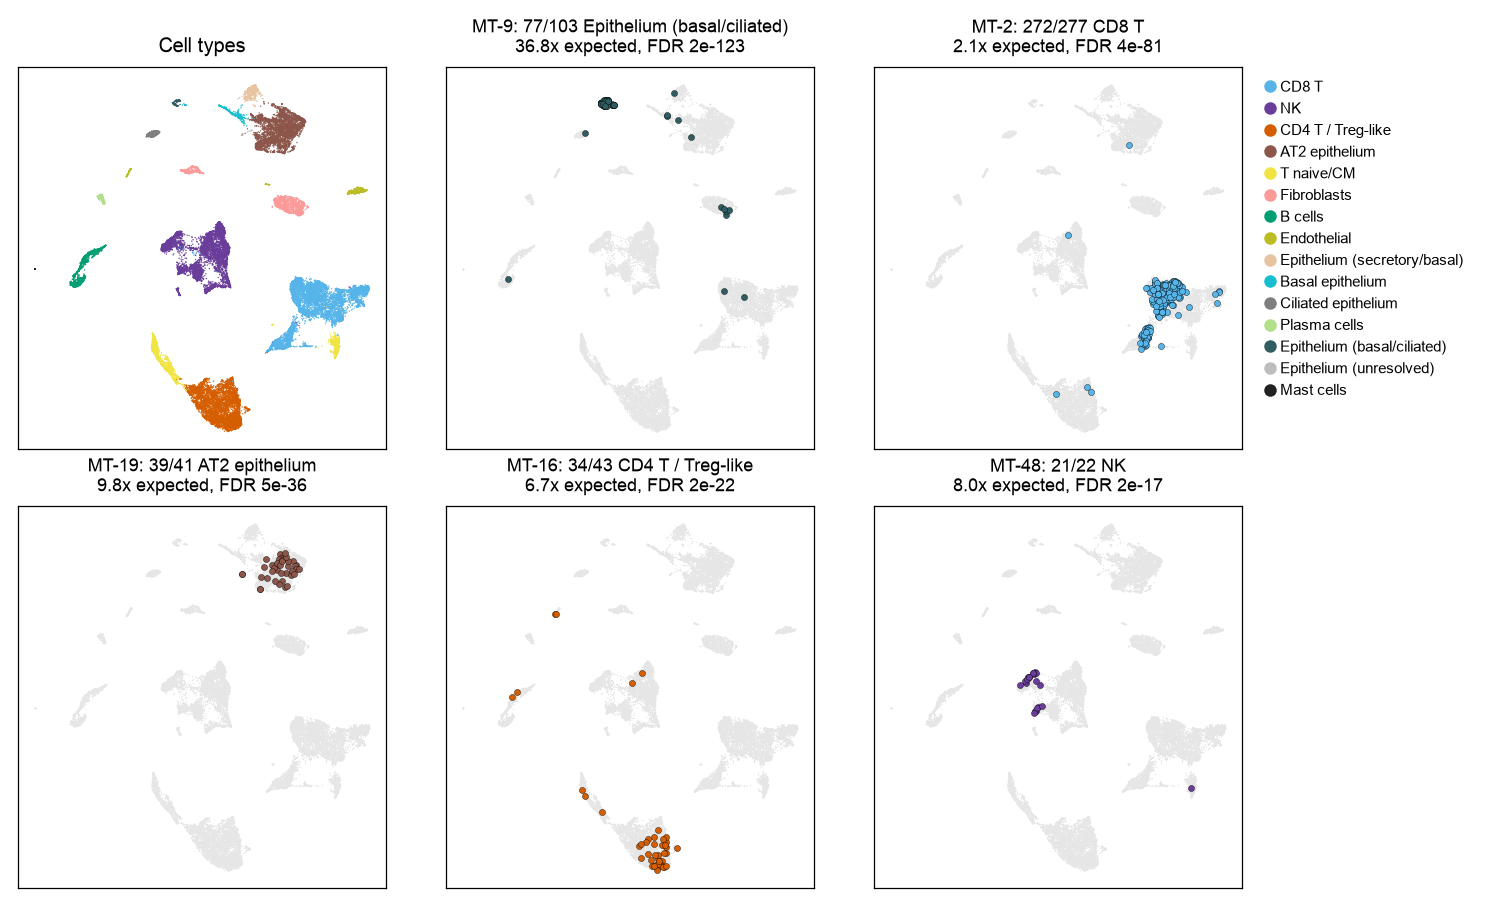

In [45]:
# one representative clone per cell type: the most significant, with at least 15 cells of that type
best = (hits[hits['n_type_in_clone'] >= 15].sort_values('p').drop_duplicates('cell_type').head(5))
umap = pd.DataFrame(g3.obsm['X_umap'], index=g3.obs_names, columns=['x', 'y'])
rng = np.random.default_rng(0)
umap = umap.iloc[rng.permutation(len(umap))]

fig, axs = plt.subplots(2, 3, figsize=(9, 6), gridspec_kw=dict(wspace=0.05, hspace=0.15))
ax = axs[0, 0]
ax.scatter(umap['x'], umap['y'], s=0.3, lw=0, rasterized=True,
           c=g3.obs['cell_type'].astype(str).reindex(umap.index).map(PALETTE).fillna('#d9d9d9'))
ax.set_title('Cell types', fontsize=8)

for ax, (_, r) in zip(axs.flat[1:], best.iterrows()):
    members = afm.obs_names[afm.obs['MiTo_clone'].astype(str) == r['clone']]
    ax.scatter(umap['x'], umap['y'], s=0.3, lw=0, color='#e6e6e6', rasterized=True)
    ax.scatter(umap.loc[members, 'x'], umap.loc[members, 'y'], s=6,
               color=PALETTE.get(r['cell_type'], 'tab:red'), edgecolor='k', linewidth=0.15)
    ax.set_title(f"{r['clone']}: {r['n_type_in_clone']}/{r['n_clone']} {r['cell_type']}\n"
                 f"{r['fold']:.1f}x expected, FDR {r['fdr']:.1g}", fontsize=7)

for ax in axs.flat:
    ax.set(xticks=[], yticks=[])
    ax.set_aspect('equal')
for ax in axs.flat[len(best) + 1:]:
    ax.axis('off')

handles = [Line2D([], [], marker='o', ls='', color=PALETTE[c], label=c, markersize=4)
           for c in g3.obs['cell_type'].astype(str).value_counts().index if c in PALETTE]
axs[0, 2].legend(handles=handles, loc='upper left', bbox_to_anchor=(1.03, 1.0), frameon=False, fontsize=6)
plt.show()

In [46]:
# where the highlighted clones come from: tissue and cell type composition
rows = {}
for _, r in best.iterrows():
    cells_of_clone = g3.obs[g3.obs['MiTo_clone'] == r['clone']]
    rows[r['clone']] = {
        'cells': len(cells_of_clone),
        'main cell type': r['cell_type'],
        **cells_of_clone['tissue'].astype(str).value_counts().to_dict(),
    }
pd.DataFrame(rows).T.fillna(0).astype({t: int for t in ['tumor', 'NILT', 'PBMC']})

,cells,main cell type,tumor,PBMC,NILT
MT-9,103,Epithelium (basal/ciliated),100,3,0
MT-2,277,CD8 T,14,220,43
MT-19,41,AT2 epithelium,0,0,41
MT-16,43,CD4 T / Treg-like,21,7,15
MT-48,22,NK,0,16,6


**Reading the UMAPs.** Each highlighted clone sits mostly inside the island of its enriched cell type; the few cells that fall elsewhere are either annotation
errors in shallow cells, or cells that joined the clone on the strength of a shared variant or two. The table shows that the clones differ in where they come from:
the epithelial clones (MT-9, basal/ciliated, and MT-19, AT2) are confined to one sample each (the tumor CD3-/CD45- and the NILT CD45- samples), as expected for cells that do not circulate;
the CD8 T clone MT-2 and the NK clone MT-48 are in blood and non-involved lung, and MT-2 also in the tumor; the CD4 clone MT-16 is found in the three tissues.
In MT-9, 9 of 103 cells are not epithelial (6 fibroblasts, 2 CD8 T and 1 B cell), the same kind of noise.
An enrichment tells where a clone sits in the annotation; it does not by itself show that the clone is restricted to that cell type.

**Summary.** Per-sample relative QC keeps 52,923 of 67,027 cells. The 18,218 cells without a clear lineage
and four doubtful islands are removed, leaving **30,807 cells** in 23 clusters.
Immune cell types follow the sort design and are supported by marker activity (bubble plot) and by promoter
accessibility (coverage), except those merged in section 6. The epithelium is split with the paper's marker
panels; clusters that mix two panels, or are too small, are named as such and not forced into one type.

Only these cells enter the MT pipeline (filter1, per-sample variants, pooled genotyping, tree): 4,732 cells x 345 variants, 209 clones (94% of cells assigned). The variant 16261_C>T is called at 8-10% in every sample, and is removed as germline-like: left in, it formed one 'clone' of a third of the cells spread over all samples and cell types.

Of the 51 clones with more than 20 cells, 44 are enriched (one-sided Fisher's exact test, FDR < 0.05) in at least one cell type. The strongest are tissue-restricted epithelial clones
(MT-9, tumor basal/ciliated epithelium; MT-19, AT2 in non-involved lung) and T/NK clones, among them a CD8 T clone found in blood, non-involved lung and tumor (MT-2).
Cell types follow the sort design, so these enrichments describe where a clone sits in the annotation, not a lineage restriction.

## Check against the reference outputs

The record also holds the outputs of this notebook (`reference_*` files, a few MB; the cell type and clone of each cell, and the enrichment table). If you ran the notebook as it is, the annotation, the clones and the enrichment table should be
identical to them.

In [47]:
reference = pd.read_csv(REFERENCE_CELLS, index_col=0)
reference_enrichment = pd.read_csv(REFERENCE_ENRICHMENT)

print(f'same cells: {g3.obs_names.equals(reference.index)}')
for column in ['cell_type', 'MiTo_clone']:
    print(f'{column}: {100 * (g3.obs[column].astype(str).values == reference[column].astype(str).values).mean():.1f}% of the cells identical')
print(f"enrichment table: largest difference in -log10 p = {np.abs(reference_enrichment['-log10 p'].values - enrich['-log10 p'].values).max():.2g}")

same cells: True
cell_type: 100.0% of the cells identical
MiTo_clone: 100.0% of the cells identical
enrichment table: largest difference in -log10 p = 1.4e-14


## Clean up

The tile matrices are the large intermediates of this notebook (a few GB). They are not needed once the notebook has run.

In [48]:
KEEP_INTERMEDIATES = False

if not KEEP_INTERMEDIATES:
    for name in ['qc_filtered.h5ad', 'tiles.h5ad', 'tiles_assigned.h5ad', 'tiles_final.h5ad']:
        (OUT / name).unlink(missing_ok=True)
print(f'kept in {OUT.name}/:', sorted(path.name for path in OUT.iterdir()))

kept in results/: ['annotation.csv', 'atac_annotated_clones.h5ad', 'clone_celltype_enrichment.csv', 'coverage.pkl', 'mt_afm.h5ad', 'mt_tree.pkl']


## References

1. Liu, V. et al. Clonal lineage tracing of innate immune cells in human cancer. *Cancer Cell* **44**, 1509-1521.e4 (2026). [doi:10.1016/j.ccell.2026.05.006](https://doi.org/10.1016/j.ccell.2026.05.006)
2. Zhang, K., Zemke, N. R., Armand, E. J. & Ren, B. A fast, scalable and versatile tool for analysis of single-cell omics data. *Nat. Methods* **21**, 217-227 (2024). [doi:10.1038/s41592-023-02139-9](https://doi.org/10.1038/s41592-023-02139-9)
3. Cossa, A., Dalmasso, A. et al. MiTo: tracing the phenotypic evolution of somatic cell lineages via mitochondrial single-cell multi-omics. *Nat. Commun.* **17**, 6794 (2026). [doi:10.1038/s41467-026-71607-5](https://doi.org/10.1038/s41467-026-71607-5)
4. Heumos, L. et al. Best practices for single-cell analysis across modalities. *Nat. Rev. Genet.* **24**, 550-572 (2023). [doi:10.1038/s41576-023-00586-w](https://doi.org/10.1038/s41576-023-00586-w)
5. Wolock, S. L., Lopez, R. & Klein, A. M. Scrublet: computational identification of cell doublets in single-cell transcriptomic data. *Cell Syst.* **8**, 281-291 (2019). [doi:10.1016/j.cels.2018.11.005](https://doi.org/10.1016/j.cels.2018.11.005)
6. Wolf, F. A., Angerer, P. & Theis, F. J. SCANPY: large-scale single-cell gene expression data analysis. *Genome Biol.* **19**, 15 (2018). [doi:10.1186/s13059-017-1382-0](https://doi.org/10.1186/s13059-017-1382-0)
7. Traag, V. A., Waltman, L. & van Eck, N. J. From Louvain to Leiden: guaranteeing well-connected communities. *Sci. Rep.* **9**, 5233 (2019). [doi:10.1038/s41598-019-41695-z](https://doi.org/10.1038/s41598-019-41695-z)
8. Jones, M. G. et al. Inference of single-cell phylogenies from lineage tracing data using Cassiopeia. *Genome Biol.* **21**, 92 (2020). [doi:10.1186/s13059-020-02000-8](https://doi.org/10.1186/s13059-020-02000-8)
9. Benjamini, Y. & Hochberg, Y. Controlling the false discovery rate: a practical and powerful approach to multiple testing. *J. R. Stat. Soc. B* **57**, 289-300 (1995). [doi:10.1111/j.2517-6161.1995.tb02031.x](https://doi.org/10.1111/j.2517-6161.1995.tb02031.x)